In [ ]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
excel_file = pd.ExcelFile("online_retail_II.xlsx")

excel_file.sheet_names

['Year 2009-2010', 'Year 2010-2011']

In [ ]:
df_1 = pd.read_excel("online_retail_II.xlsx", sheet_name="Year 2009-2010")

df_2 = pd.read_excel("online_retail_II.xlsx", sheet_name="Year 2010-2011")

df_1.shape, df_2.shape

((525461, 8), (541910, 8))

In [ ]:
df_1.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [ ]:
df_2.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
df = pd.concat([df_1, df_2], ignore_index=True)

df.shape

(1067371, 8)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [ ]:
df.isna().sum()

,0
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


In [ ]:
df["Invoice"].astype(str).str.startswith("C").value_counts()

,count
Invoice,
False,1047877
True,19494


In [ ]:
id_counts = df.groupby(df["Invoice"].astype(str).str.startswith("C"))["Customer ID"].apply(lambda x: x.notna().sum())

id_counts

,Customer ID
Invoice,
False,805620
True,18744


In [ ]:
df.groupby(df["Invoice"].astype(str).str.startswith("C"))["Customer ID"].apply(lambda x: x.isna().sum())

,Customer ID
Invoice,
False,242257
True,750


In [ ]:
df["Quantity"].describe()

,Quantity
count,1.067371e+06
mean,9.938898e+00
std,1.727058e+02
min,-8.099500e+04
25%,1.000000e+00
50%,3.000000e+00
75%,1.000000e+01
max,8.099500e+04


In [ ]:
df[df["Quantity"] < 0][["Invoice", "StockCode", "Quantity", "InvoiceDate", "Customer ID"]].head(10)

,Invoice,StockCode,Quantity,InvoiceDate,Customer ID
178,C489449,22087,-12,2009-12-01 10:33:00,16321.0
179,C489449,85206A,-6,2009-12-01 10:33:00,16321.0
180,C489449,21895,-4,2009-12-01 10:33:00,16321.0
181,C489449,21896,-6,2009-12-01 10:33:00,16321.0
182,C489449,22083,-12,2009-12-01 10:33:00,16321.0
183,C489449,21871,-12,2009-12-01 10:33:00,16321.0
184,C489449,84946,-12,2009-12-01 10:33:00,16321.0
185,C489449,84970S,-24,2009-12-01 10:33:00,16321.0
186,C489449,22090,-12,2009-12-01 10:33:00,16321.0
196,C489459,90200A,-3,2009-12-01 10:44:00,17592.0


In [ ]:
df[(df["Quantity"] < 0) & (~df["Invoice"].astype(str).str.startswith("C"))][["Invoice", "StockCode", "Quantity", "InvoiceDate", "Customer ID"]].head(10)

,Invoice,StockCode,Quantity,InvoiceDate,Customer ID
263,489464,21733,-96,2009-12-01 10:52:00,NaN
283,489463,71477,-240,2009-12-01 10:52:00,NaN
284,489467,85123A,-192,2009-12-01 10:53:00,NaN
470,489521,21646,-50,2009-12-01 11:44:00,NaN
3114,489655,20683,-44,2009-12-01 17:26:00,NaN
3162,489660,35956,-1043,2009-12-01 17:43:00,NaN
3168,489663,35605A,-117,2009-12-01 18:02:00,NaN
4296,489806,18010,-770,2009-12-02 12:42:00,NaN
4538,489820,21133,-720,2009-12-02 13:23:00,NaN
4566,489821,85049G,-240,2009-12-02 13:25:00,NaN


In [ ]:
df[df["Quantity"] < 0]["StockCode"].value_counts().head(20)

,count
StockCode,
M,537
22423,359
POST,229
22138,213
21232,190
D,172
21843,163
85123A,137
79323W,128


In [ ]:
df[df["StockCode"].isin(["M", "POST", "D", "S"])][["StockCode", "Description", "Quantity", "Price", "Invoice"]].head(30)

,StockCode,Description,Quantity,Price,Invoice
89,POST,POSTAGE,3,18.00,489439
126,POST,POSTAGE,1,141.00,489444
173,POST,POSTAGE,1,130.00,489447
625,POST,POSTAGE,6,18.00,489526
735,D,Discount,-1,9.00,C489535
736,D,Discount,-1,19.00,C489535
927,POST,POSTAGE,-1,9.58,C489538
1244,POST,POSTAGE,4,18.00,489557
2697,M,Manual,1,4.00,489609
3053,M,Manual,-1,5.10,C489651


In [ ]:
df[df["StockCode"] == "S"][["StockCode", "Description", "Quantity", "Price", "Invoice"]].head(20)

,StockCode,Description,Quantity,Price,Invoice
114061,S,SAMPLES,-1,73.80,C500305
114083,S,SAMPLES,-1,32.03,C500309
133558,S,SAMPLES,-1,170.37,C502083
133582,S,SAMPLES,-1,259.59,C502088
136253,S,SAMPLES,-1,605.18,C502438
136259,S,SAMPLES,-1,94.19,C502442
181508,S,SAMPLES,1,73.80,506601
181509,S,SAMPLES,-1,3.84,C506602
181510,S,SAMPLES,-1,3.55,C506602
181511,S,SAMPLES,-1,77.00,C506602


In [ ]:
special_codes = ["M", "POST", "D", "S"]

df[df["StockCode"].isin(special_codes)]["StockCode"].value_counts()

,count
StockCode,
POST,2122
M,1421
D,177
S,104


In [ ]:
df["Price"].describe()

,Price
count,1.067371e+06
mean,4.649388e+00
std,1.235531e+02
min,-5.359436e+04
25%,1.250000e+00
50%,2.100000e+00
75%,4.150000e+00
max,3.897000e+04


In [ ]:
df[df["Price"] <= 0][["Invoice", "StockCode", "Description", "Quantity", "Price", "Customer ID"]].head(20)

,Invoice,StockCode,Description,Quantity,Price,Customer ID
263,489464,21733,85123a mixed,-96,0.0,NaN
283,489463,71477,short,-240,0.0,NaN
284,489467,85123A,21733 mixed,-192,0.0,NaN
470,489521,21646,NaN,-50,0.0,NaN
3114,489655,20683,NaN,-44,0.0,NaN
3161,489659,21350,NaN,230,0.0,NaN
3162,489660,35956,lost,-1043,0.0,NaN
3168,489663,35605A,damages,-117,0.0,NaN
3731,489781,84292,NaN,17,0.0,NaN
4296,489806,18010,NaN,-770,0.0,NaN


In [ ]:
(df["Price"] <= 0).sum()

np.int64(6207)

In [ ]:
df[df["Price"] < 0][
    ["Invoice", "StockCode", "Description", "Quantity", "Price", "Customer ID"]
]

,Invoice,StockCode,Description,Quantity,Price,Customer ID
179403,A506401,B,Adjust bad debt,1,-53594.36,NaN
276274,A516228,B,Adjust bad debt,1,-44031.79,NaN
403472,A528059,B,Adjust bad debt,1,-38925.87,NaN
825444,A563186,B,Adjust bad debt,1,-11062.06,NaN
825445,A563187,B,Adjust bad debt,1,-11062.06,NaN


In [ ]:
(df["Price"] == 0).sum()

np.int64(6202)

In [ ]:
df["Description"].isna().sum()

np.int64(4382)

In [ ]:
df[df["Description"].isna()]["Customer ID"].notna().value_counts()

,count
Customer ID,
False,4382


In [ ]:
df.duplicated().sum()

np.int64(34335)

In [ ]:
df[df.duplicated(keep=False)].sort_values(
    ["Invoice", "StockCode", "InvoiceDate"]
).head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom


In [ ]:
df[df.duplicated()].groupby(
    df.loc[df.duplicated(), "Invoice"].astype(str).str.startswith("C")
).size()

,0
Invoice,
False,33945
True,390


In [ ]:
df.groupby(["Invoice", "StockCode"]).size().sort_values(ascending=False).head(20)

,,0
Invoice,StockCode,
555524,22698,20
C544580,S,16
555524,22697,12
536412,21448,10
537646,22585,10
537224,70007,10
C514024,M,10
502660,17021,9
537202,22147,8


In [ ]:
df_clean = df.copy()

df_clean.shape

(1067371, 8)

In [ ]:
df_clean = df_clean.drop_duplicates()

df_clean.shape

(1033036, 8)

In [ ]:
df_clean["IsCancelled"] = df_clean["Invoice"].astype(str).str.startswith("C")

df_clean["IsCancelled"].value_counts()

,count
IsCancelled,
False,1013932
True,19104


In [ ]:
df_clean[df_clean["Quantity"] < 0].shape

(22496, 9)

In [ ]:
df_clean[df_clean["Quantity"] < 0]["IsCancelled"].value_counts()

,count
IsCancelled,
True,19103
False,3393


In [ ]:
df_clean[(df_clean["Quantity"] < 0) & (~df_clean["IsCancelled"])][["Invoice", "StockCode", "Description", "Quantity", "Price", "Customer ID"]].head(30)

,Invoice,StockCode,Description,Quantity,Price,Customer ID
263,489464,21733,85123a mixed,-96,0.0,NaN
283,489463,71477,short,-240,0.0,NaN
284,489467,85123A,21733 mixed,-192,0.0,NaN
470,489521,21646,NaN,-50,0.0,NaN
3114,489655,20683,NaN,-44,0.0,NaN
3162,489660,35956,lost,-1043,0.0,NaN
3168,489663,35605A,damages,-117,0.0,NaN
4296,489806,18010,NaN,-770,0.0,NaN
4538,489820,21133,invcd as 84879?,-720,0.0,NaN
4566,489821,85049G,NaN,-240,0.0,NaN


In [ ]:
df_clean[
    (df_clean["Quantity"] < 0) &
    (~df_clean["IsCancelled"])
]["Customer ID"].notna().value_counts()

,count
Customer ID,
False,3393


In [ ]:
df_clean[
    (df_clean["IsCancelled"] == False) &
    (df_clean["Quantity"] > 0) &
    (df_clean["Customer ID"].isna())
].shape

(231044, 9)

In [ ]:
df_clean[
    (df_clean["IsCancelled"] == False) &
    (df_clean["Quantity"] > 0) &
    (df_clean["Customer ID"].notna())
].shape

(779495, 9)

In [ ]:
df_clean[
    (df_clean["IsCancelled"] == False) &
    (df_clean["Quantity"] > 0) &
    (df_clean["Customer ID"].notna())
]["Customer ID"].nunique()

5881

In [ ]:
df_clean["InvoiceDate"].agg(["min", "max"])

,InvoiceDate
min,2009-12-01 07:45:00
max,2011-12-09 12:50:00


In [ ]:
sales = df_clean[
    (df_clean["IsCancelled"] == False) &
    (df_clean["Quantity"] > 0)
].copy()

sales.shape

(1010539, 9)

In [ ]:
customer_sales = sales[sales["Customer ID"].notna()].copy()

customer_sales.shape

(779495, 9)

In [ ]:
customer_sales["Revenue"] = (customer_sales["Quantity"] * customer_sales["Price"])

customer_sales[["Quantity", "Price", "Revenue"]].head()

,Quantity,Price,Revenue
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0


In [ ]:
customer_sales["Revenue"].describe()

,Revenue
count,779495.000000
mean,22.289821
std,227.416962
min,0.000000
25%,4.950000
50%,12.480000
75%,19.800000
max,168469.600000


In [ ]:
(customer_sales["Revenue"] == 0).sum()

np.int64(70)

In [ ]:
customer_sales = customer_sales[customer_sales["Revenue"] > 0].copy()

customer_sales.shape

(779425, 10)

In [ ]:
customer_sales["Customer ID"].nunique()

5878

In [ ]:
customer_sales["Invoice"].nunique()

36969

In [ ]:
orders_per_customer = (
    customer_sales.groupby("Customer ID")["Invoice"]
    .nunique()
)

orders_per_customer.describe()

,Invoice
count,5878.000000
mean,6.289384
std,13.009406
min,1.000000
25%,1.000000
50%,3.000000
75%,7.000000
max,398.000000


In [ ]:
orders_per_customer.value_counts().sort_index().head(15)

,count
Invoice,
1,1623
2,944
3,664
4,486
5,360
6,280
7,222
8,172
9,153


In [ ]:
customer_summary = orders_per_customer.reset_index()

customer_summary["IsRepeatCustomer"] = (customer_summary["Invoice"] > 1)

customer_summary["IsRepeatCustomer"].value_counts()

,count
IsRepeatCustomer,
True,4255
False,1623


In [ ]:
customer_dates = (
    customer_sales.groupby("Customer ID")["InvoiceDate"]
    .agg(["min", "max"])
    .reset_index()
)

customer_dates.head()

,Customer ID,min,max
0,12346.0,2009-12-14 08:34:00,2011-01-18 10:01:00
1,12347.0,2010-10-31 14:20:00,2011-12-07 15:52:00
2,12348.0,2010-09-27 14:59:00,2011-09-25 13:13:00
3,12349.0,2010-04-29 13:20:00,2011-11-21 09:51:00
4,12350.0,2011-02-02 16:01:00,2011-02-02 16:01:00


In [ ]:
customer_sales["InvoiceDate"].max()

Timestamp('2011-12-09 12:50:00')

In [ ]:
observation_end = customer_sales["InvoiceDate"].max()

customer_dates["Has90DaysObservation"] = (customer_dates["min"] + pd.Timedelta(days=90) <= observation_end)

customer_dates["Has90DaysObservation"].value_counts()

,count
Has90DaysObservation,
True,5281
False,597


In [ ]:
eligible_customers = customer_dates[
    customer_dates["Has90DaysObservation"]
]["Customer ID"]

customer_sales_90d = customer_sales[
    customer_sales["Customer ID"].isin(eligible_customers)
].copy()

customer_sales_90d.shape

(752407, 10)

In [ ]:
first_purchase = (
    customer_sales_90d
    .groupby("Customer ID")["InvoiceDate"]
    .min()
    .rename("FirstPurchaseDate")
)

customer_sales_90d = customer_sales_90d.merge(
    first_purchase,
    on="Customer ID",
    how="left"
)

customer_sales_90d["DaysSinceFirstPurchase"] = (
    customer_sales_90d["InvoiceDate"] - customer_sales_90d["FirstPurchaseDate"]
).dt.days

customer_sales_90d["DaysSinceFirstPurchase"].describe()

,DaysSinceFirstPurchase
count,752407.000000
mean,257.212214
std,220.297322
min,0.000000
25%,54.000000
50%,217.000000
75%,418.000000
max,738.000000


In [ ]:
customer_sales_90d["OrderNumber"] = (
    customer_sales_90d
    .sort_values(["Customer ID", "InvoiceDate"])
    .groupby("Customer ID")["Invoice"]
    .transform(lambda x: pd.factorize(x)[0] + 1)
)

customer_sales_90d[["Customer ID", "Invoice", "InvoiceDate", "OrderNumber"]].head(20)

,Customer ID,Invoice,InvoiceDate,OrderNumber
0,13085.0,489434,2009-12-01 07:45:00,1
1,13085.0,489434,2009-12-01 07:45:00,1
2,13085.0,489434,2009-12-01 07:45:00,1
3,13085.0,489434,2009-12-01 07:45:00,1
4,13085.0,489434,2009-12-01 07:45:00,1
5,13085.0,489434,2009-12-01 07:45:00,1
6,13085.0,489434,2009-12-01 07:45:00,1
7,13085.0,489434,2009-12-01 07:45:00,1
8,13085.0,489435,2009-12-01 07:46:00,2
9,13085.0,489435,2009-12-01 07:46:00,2


In [ ]:
second_purchase = (
    customer_sales_90d[
   customer_sales_90d["OrderNumber"] == 2
    ]
    .groupby("Customer ID")["InvoiceDate"]
    .min()
    .rename("SecondPurchaseDate")
)

second_purchase.head()

,SecondPurchaseDate
Customer ID,
12346.0,2009-12-14 11:00:00
12347.0,2010-12-07 14:57:00
12348.0,2010-12-16 19:09:00
12349.0,2010-05-18 09:57:00
12352.0,2010-11-29 10:07:00


In [ ]:
first_purchase = first_purchase.rename("FirstPurchaseDate")

purchase_gap = pd.concat(
    [first_purchase, second_purchase],
    axis=1
).dropna()

purchase_gap["DaysToSecondPurchase"] = (
    purchase_gap["SecondPurchaseDate"]
    - purchase_gap["FirstPurchaseDate"]
).dt.total_seconds() / (24 * 60 * 60)

purchase_gap["DaysToSecondPurchase"].describe()

,DaysToSecondPurchase
count,4023.000000
mean,101.675532
std,114.627722
min,0.000000
25%,21.450000
50%,60.793056
75%,137.560069
max,714.152083


In [ ]:
purchase_gap["RepeatWithin90Days"] = (purchase_gap["DaysToSecondPurchase"] <= 90)

purchase_gap["RepeatWithin90Days"].value_counts()

,count
RepeatWithin90Days,
True,2486
False,1537


In [ ]:
repeat_90d_rate = (purchase_gap["RepeatWithin90Days"].sum() / len(eligible_customers))

repeat_90d_rate

np.float64(0.47074417723915923)

In [ ]:
first_order_revenue = (
    customer_sales_90d[
   customer_sales_90d["OrderNumber"] == 1
    ]
    .groupby("Customer ID")["Revenue"]
    .sum()
    .rename("FirstOrderRevenue")
)

first_order_revenue.describe()

,FirstOrderRevenue
count,5281.000000
mean,411.925080
std,756.898105
min,1.300000
25%,166.240000
50%,293.530000
75%,446.620000
max,33167.800000


In [ ]:
first_order_quantity = (
    customer_sales_90d[
   customer_sales_90d["OrderNumber"] == 1
    ]
    .groupby("Customer ID")["Quantity"]
    .sum()
    .rename("FirstOrderQuantity")
)

first_order_quantity.describe()

,FirstOrderQuantity
count,5281.000000
mean,259.370384
std,1294.589433
min,1.000000
25%,79.000000
50%,150.000000
75%,277.000000
max,87167.000000


In [ ]:
customer_country = (
    customer_sales_90d
    .groupby("Customer ID")["Country"]
    .first()
    .rename("Country")
)

customer_country.value_counts().head(15)

,count
Country,
United Kingdom,4813
Germany,93
France,76
Spain,34
Belgium,26
Netherlands,22
Portugal,20
Switzerland,19
Sweden,19


In [ ]:
customer_country.value_counts()

,count
Country,
United Kingdom,4813
Germany,93
France,76
Spain,34
Belgium,26
Netherlands,22
Portugal,20
Switzerland,19
Sweden,19


In [ ]:
customer_features = (
    customer_dates[
   customer_dates["Has90DaysObservation"]
    ][["Customer ID", "min"]]
    .rename(columns={"min": "FirstPurchaseDate"})
    .merge(first_order_revenue, on="Customer ID")
    .merge(first_order_quantity, on="Customer ID")
    .merge(customer_country, on="Customer ID")
    .merge(
   purchase_gap[["RepeatWithin90Days", "DaysToSecondPurchase"]],
   on="Customer ID",
   how="left"
    )
)

customer_features.shape

(5281, 7)

In [ ]:
customer_features.isna().sum()

,0
Customer ID,0
FirstPurchaseDate,0
FirstOrderRevenue,0
FirstOrderQuantity,0
Country,0
RepeatWithin90Days,1258
DaysToSecondPurchase,1258


In [ ]:
customer_features["RepeatWithin90Days"] = (customer_features["RepeatWithin90Days"].fillna(False))

customer_features["RepeatWithin90Days"].value_counts()

/tmp/ipykernel_1164/3350886424.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  customer_features["RepeatWithin90Days"] = (customer_features["RepeatWithin90Days"].fillna(False))


,count
RepeatWithin90Days,
False,2795
True,2486


In [ ]:
customer_features["FirstOrderRevenueGroup"] = pd.qcut(
    customer_features["FirstOrderRevenue"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

customer_features.groupby(
    "FirstOrderRevenueGroup",
    observed=True
)["FirstOrderRevenue"].agg(["count", "min", "median", "max"])

,count,min,median,max
FirstOrderRevenueGroup,,,,
Q1,1321,1.30,115.200,166.24
Q2,1320,166.50,222.140,293.53
Q3,1320,293.74,341.655,446.62
Q4,1320,446.94,681.415,33167.80


In [ ]:
repeat_by_revenue = (
    customer_features
    .groupby("FirstOrderRevenueGroup", observed=True)["RepeatWithin90Days"]
    .agg(["count", "sum", "mean"])
)

repeat_by_revenue

,count,sum,mean
FirstOrderRevenueGroup,,,
Q1,1321,477,0.361090
Q2,1320,596,0.451515
Q3,1320,654,0.495455
Q4,1320,759,0.575000


In [ ]:
customer_features["FirstOrderQuantityGroup"] = pd.qcut(
    customer_features["FirstOrderQuantity"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

customer_features.groupby(
    "FirstOrderQuantityGroup",
    observed=True
)["FirstOrderQuantity"].agg(["count", "min", "median", "max"])

,count,min,median,max
FirstOrderQuantityGroup,,,,
Q1,1329,1,48.0,79
Q2,1315,80,110.0,150
Q3,1320,151,202.0,277
Q4,1317,278,425.0,87167


In [ ]:
repeat_by_quantity = (
    customer_features
    .groupby("FirstOrderQuantityGroup", observed=True)["RepeatWithin90Days"]
    .agg(["count", "sum", "mean"])
)

repeat_by_quantity

,count,sum,mean
FirstOrderQuantityGroup,,,
Q1,1329,516,0.388262
Q2,1315,563,0.428137
Q3,1320,678,0.513636
Q4,1317,729,0.553531


In [ ]:
country_counts = customer_features["Country"].value_counts()

valid_countries = country_counts[country_counts >= 30].index

customer_features_country = customer_features[customer_features["Country"].isin(valid_countries)].copy()

customer_features_country["Country"].value_counts()

,count
Country,
United Kingdom,4813
Germany,93
France,76
Spain,34


In [ ]:
repeat_by_country = (
    customer_features_country
    .groupby("Country")["RepeatWithin90Days"]
    .agg(["count", "sum", "mean"])
    .sort_values("mean", ascending=False)
)

repeat_by_country

,count,sum,mean
Country,,,
Germany,93,56,0.602151
France,76,43,0.565789
United Kingdom,4813,2252,0.467899
Spain,34,12,0.352941


In [ ]:
customer_features.groupby("RepeatWithin90Days")[["FirstOrderRevenue", "FirstOrderQuantity"]].median()

,FirstOrderRevenue,FirstOrderQuantity
RepeatWithin90Days,,
False,252.520,131.0
True,313.725,173.0


In [ ]:
from scipy.stats import mannwhitneyu

repeat_group = customer_features[
    customer_features["RepeatWithin90Days"] == True
]["FirstOrderRevenue"]

non_repeat_group = customer_features[
    customer_features["RepeatWithin90Days"] == False
]["FirstOrderRevenue"]

mannwhitneyu(
    repeat_group,
    non_repeat_group,
    alternative="two-sided"
)

MannwhitneyuResult(statistic=np.float64(4120946.0), pvalue=np.float64(1.3547809506852658e-31))

In [ ]:
repeat_quantity_group = customer_features[
    customer_features["RepeatWithin90Days"] == True
]["FirstOrderQuantity"]

non_repeat_quantity_group = customer_features[
    customer_features["RepeatWithin90Days"] == False
]["FirstOrderQuantity"]

mannwhitneyu(
    repeat_quantity_group,
    non_repeat_quantity_group,
    alternative="two-sided"
)

MannwhitneyuResult(statistic=np.float64(4009600.0), pvalue=np.float64(3.6137273448606027e-22))

In [ ]:
repeat_quantity_group = customer_features[
    customer_features["RepeatWithin90Days"] == True
]["FirstOrderQuantity"]

non_repeat_quantity_group = customer_features[
    customer_features["RepeatWithin90Days"] == False
]["FirstOrderQuantity"]

mannwhitneyu(
    repeat_quantity_group,
    non_repeat_quantity_group,
    alternative="two-sided"
)

MannwhitneyuResult(statistic=np.float64(4009600.0), pvalue=np.float64(3.6137273448606027e-22))

In [ ]:
customer_features["Repeat90"] = (
    customer_features["RepeatWithin90Days"].astype(int)
)

customer_features[["RepeatWithin90Days", "Repeat90"]].head()

,RepeatWithin90Days,Repeat90
0,True,1
1,True,1
2,True,1
3,True,1
4,False,0


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X = customer_features[
    ["FirstOrderRevenue", "FirstOrderQuantity"]
]

y = customer_features["Repeat90"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

logit_model = LogisticRegression()
logit_model.fit(X_scaled, y)

logit_model.coef_, logit_model.intercept_

(array([[ 0.49180345, -0.16309819]]), array([-0.10557486]))

In [ ]:
customer_features[
    ["FirstOrderRevenue", "FirstOrderQuantity"]
].corr()

,FirstOrderRevenue,FirstOrderQuantity
FirstOrderRevenue,1.000000,0.443858
FirstOrderQuantity,0.443858,1.000000


In [ ]:
customer_features["MainCountry"] = customer_features["Country"].where(
    customer_features["Country"].isin(
   ["United Kingdom", "Germany", "France", "Spain"]
    ),
    "Other"
)

customer_features["MainCountry"].value_counts()

,count
MainCountry,
United Kingdom,4813
Other,265
Germany,93
France,76
Spain,34


In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

X = customer_features[
    ["FirstOrderRevenue", "FirstOrderQuantity", "MainCountry"]
]
y = customer_features["Repeat90"]

preprocessor = ColumnTransformer(
    transformers=[
   (
   "num",
   StandardScaler(),
   ["FirstOrderRevenue", "FirstOrderQuantity"]
   ),
   (
   "cat",
   OneHotEncoder(drop="first", handle_unknown="ignore"),
   ["MainCountry"]
   )
    ]
)

logit_model_country = Pipeline(
    steps=[
   ("preprocessor", preprocessor),
   ("model", LogisticRegression())
    ]
)

logit_model_country.fit(X, y)

logit_model_country.named_steps["model"].coef_

array([[ 0.499355  , -0.16408501,  0.1055847 , -0.45799357, -0.78153168,
        -0.24321058]])

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = logit_model_country.predict(X)

print("Accuracy:", accuracy_score(y, y_pred))
print()
print(classification_report(y, y_pred))

Accuracy: 0.5631509183866692

              precision    recall  f1-score   support

           0       0.56      0.87      0.68      2795
           1       0.60      0.22      0.32      2486

    accuracy                           0.56      5281
   macro avg       0.58      0.54      0.50      5281
weighted avg       0.58      0.56      0.51      5281



In [ ]:
from sklearn.metrics import roc_auc_score

y_proba = logit_model_country.predict_proba(X)[:, 1]

roc_auc = roc_auc_score(y, y_proba)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.5936372847156959


In [ ]:
first_order_unique_products = (
    customer_sales_90d[
   customer_sales_90d["OrderNumber"] == 1
    ]
    .groupby("Customer ID")["StockCode"]
    .nunique()
    .rename("FirstOrderUniqueProducts")
)

customer_features = customer_features.merge(
    first_order_unique_products,
    on="Customer ID",
    how="left"
)

customer_features["FirstOrderUniqueProducts"].describe()

,FirstOrderUniqueProducts
count,5281.000000
mean,23.718614
std,22.460613
min,1.000000
25%,9.000000
50%,18.000000
75%,31.000000
max,250.000000


In [ ]:
customer_features.groupby("RepeatWithin90Days")[
    "FirstOrderUniqueProducts"
].agg(["count", "median", "mean"])

,count,median,mean
RepeatWithin90Days,,,
False,2795,17.0,21.677281
True,2486,20.0,26.013677


In [ ]:
repeat_products = customer_features[
    customer_features["RepeatWithin90Days"] == True
]["FirstOrderUniqueProducts"]

non_repeat_products = customer_features[
    customer_features["RepeatWithin90Days"] == False
]["FirstOrderUniqueProducts"]

mannwhitneyu(
    repeat_products,
    non_repeat_products,
    alternative="two-sided"
)

MannwhitneyuResult(statistic=np.float64(3885257.5), pvalue=np.float64(1.0438439028035764e-13))

In [ ]:
X = customer_features[
    [
   "FirstOrderRevenue",
   "FirstOrderQuantity",
   "FirstOrderUniqueProducts",
   "MainCountry"
    ]
]

y = customer_features["Repeat90"]

preprocessor = ColumnTransformer(
    transformers=[
   (
   "num",
   StandardScaler(),
   [
  "FirstOrderRevenue",
  "FirstOrderQuantity",
  "FirstOrderUniqueProducts"
   ]
   ),
   (
   "cat",
   OneHotEncoder(drop="first", handle_unknown="ignore"),
   ["MainCountry"]
   )
    ]
)

logit_model_final = Pipeline(
    steps=[
   ("preprocessor", preprocessor),
   ("model", LogisticRegression())
    ]
)

logit_model_final.fit(X, y)

y_proba = logit_model_final.predict_proba(X)[:, 1]

print("ROC-AUC:", roc_auc_score(y, y_proba))

ROC-AUC: 0.5908243947861154


In [ ]:
customer_features["LogFirstOrderRevenue"] = np.log1p(
    customer_features["FirstOrderRevenue"]
)

customer_features["LogFirstOrderQuantity"] = np.log1p(
    customer_features["FirstOrderQuantity"]
)

customer_features[
    [
   "FirstOrderRevenue",
   "LogFirstOrderRevenue",
   "FirstOrderQuantity",
   "LogFirstOrderQuantity"
    ]
].describe()

,FirstOrderRevenue,LogFirstOrderRevenue,FirstOrderQuantity,LogFirstOrderQuantity
count,5281.000000,5281.000000,5281.000000,5281.000000
mean,411.925080,5.623852,259.370384,4.943156
std,756.898105,0.861090,1294.589433,1.110498
min,1.300000,0.832909,1.000000,0.693147
25%,166.240000,5.119430,79.000000,4.382027
50%,293.530000,5.685381,150.000000,5.017280
75%,446.620000,6.103945,277.000000,5.627621
max,33167.800000,10.409365,87167.000000,11.375593


In [ ]:
X_log = customer_features[
    [
   "LogFirstOrderRevenue",
   "LogFirstOrderQuantity",
   "FirstOrderUniqueProducts",
   "MainCountry"
    ]
]

y = customer_features["Repeat90"]

preprocessor_log = ColumnTransformer(
    transformers=[
   (
   "num",
   StandardScaler(),
   [
  "LogFirstOrderRevenue",
  "LogFirstOrderQuantity",
  "FirstOrderUniqueProducts"
   ]
   ),
   (
   "cat",
   OneHotEncoder(drop="first", handle_unknown="ignore"),
   ["MainCountry"]
   )
    ]
)

logit_model_log = Pipeline(
    steps=[
   ("preprocessor", preprocessor_log),
   ("model", LogisticRegression())
    ]
)

logit_model_log.fit(X_log, y)

y_proba_log = logit_model_log.predict_proba(X_log)[:, 1]

print("ROC-AUC:", roc_auc_score(y, y_proba_log))

ROC-AUC: 0.5973911147506538


In [ ]:
feature_names = (
    ["LogFirstOrderRevenue",
"LogFirstOrderQuantity",
"FirstOrderUniqueProducts"]
    + list(
   logit_model_log
   .named_steps["preprocessor"]
   .named_transformers_["cat"]
   .get_feature_names_out(["MainCountry"])
    )
)

coefficients = logit_model_log.named_steps["model"].coef_[0]

pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
}).sort_values("Coefficient", ascending=False)

,Feature,Coefficient
0,LogFirstOrderRevenue,0.282477
3,MainCountry_Germany,0.091323
2,FirstOrderUniqueProducts,0.059612
1,LogFirstOrderQuantity,0.002059
6,MainCountry_United Kingdom,-0.215458
4,MainCountry_Other,-0.429131
5,MainCountry_Spain,-0.709611


In [ ]:
customer_features["LogRevenueGroup"] = pd.qcut(
    customer_features["LogFirstOrderRevenue"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

repeat_by_log_revenue = (
    customer_features
    .groupby("LogRevenueGroup", observed=False)["Repeat90"]
    .agg(["count", "sum", "mean"])
)

repeat_by_log_revenue

,count,sum,mean
LogRevenueGroup,,,
Q1,1321,477,0.361090
Q2,1320,596,0.451515
Q3,1320,654,0.495455
Q4,1320,759,0.575000


In [ ]:
purchase_gap["DaysToSecondPurchase"].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
)

,DaysToSecondPurchase
count,4023.000000
mean,101.675532
std,114.627722
min,0.000000
10%,4.083056
25%,21.450000
50%,60.793056
75%,137.560069
90%,268.691389
max,714.152083


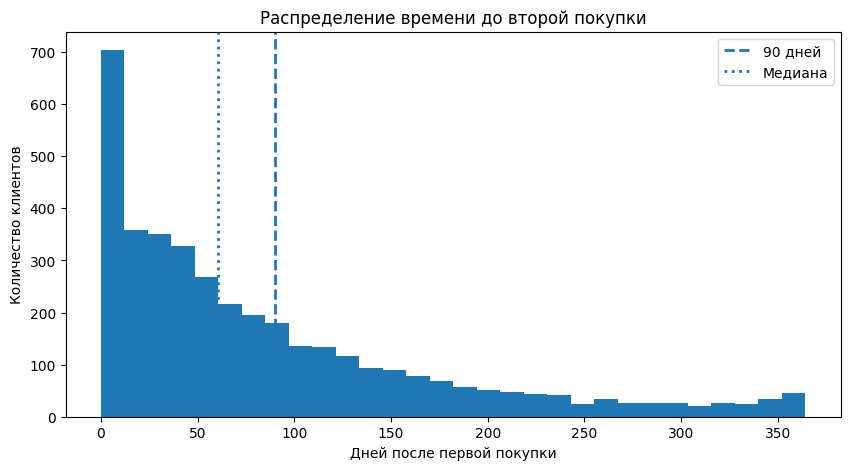

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    purchase_gap["DaysToSecondPurchase"][
   purchase_gap["DaysToSecondPurchase"] <= 365
    ],
    bins=30
)

plt.axvline(
    90,
    linestyle="--",
    linewidth=2,
    label="90 дней"
)

plt.axvline(
    purchase_gap["DaysToSecondPurchase"].median(),
    linestyle=":",
    linewidth=2,
    label="Медиана"
)

plt.title("Распределение времени до второй покупки")
plt.xlabel("Дней после первой покупки")
plt.ylabel("Количество клиентов")
plt.legend()

plt.show()

In [ ]:
windows = [7, 30, 60, 90, 180]

repeat_rates = {}

for days in windows:
    repeat_rates[days] = (
   customer_features["DaysToSecondPurchase"].le(days).fillna(False).sum()
   / len(customer_features)
    )

pd.DataFrame({
    "WindowDays": windows,
    "RepeatRate": [repeat_rates[d] for d in windows]
})

,WindowDays,RepeatRate
0,7,0.096005
1,30,0.229881
2,60,0.379284
3,90,0.470744
4,180,0.625639


In [ ]:
observation_end = customer_sales["InvoiceDate"].max()

customer_dates["Has180DaysObservation"] = (
    customer_dates["min"] + pd.Timedelta(days=180) <= observation_end
)

customer_dates["Has180DaysObservation"].value_counts()

,count
Has180DaysObservation,
True,4977
False,901


In [ ]:
eligible_180d = customer_dates[
    customer_dates["Has180DaysObservation"]
]["Customer ID"]

repeat_180d = (
    purchase_gap.loc[
   purchase_gap.index.isin(eligible_180d),
   "DaysToSecondPurchase"
    ].le(180).sum()
)

repeat_180d_rate = repeat_180d / len(eligible_180d)

print("Клиентов с 180 днями наблюдения:", len(eligible_180d))
print("Повторили покупку за 180 дней:", repeat_180d)
print("Repeat rate 180d:", repeat_180d_rate)

Клиентов с 180 днями наблюдения: 4977
Повторили покупку за 180 дней: 3106
Repeat rate 180d: 0.6240707253365482


In [ ]:
windows = [7, 30, 60, 90, 180]

retention_results = []

for days in windows:
    eligible = customer_dates[
   customer_dates["min"] + pd.Timedelta(days=days)
   <= observation_end
    ]["Customer ID"]

    repeat_rate = (
   purchase_gap.loc[
   purchase_gap.index.isin(eligible),
   "DaysToSecondPurchase"
   ].le(days).sum()
   / len(eligible)
    )

    retention_results.append({
   "WindowDays": days,
   "EligibleCustomers": len(eligible),
   "RepeatCustomers": purchase_gap.loc[
   purchase_gap.index.isin(eligible),
   "DaysToSecondPurchase"
   ].le(days).sum(),
   "RepeatRate": repeat_rate
    })

retention_table = pd.DataFrame(retention_results)

retention_table

,WindowDays,EligibleCustomers,RepeatCustomers,RepeatRate
0,7,5856,507,0.086578
1,30,5717,1214,0.212349
2,60,5518,2003,0.362994
3,90,5281,2486,0.470744
4,180,4977,3106,0.624071


Блок 2: Экономика лояльности

In [ ]:
customer_value = (
    customer_sales
    .groupby("Customer ID")
    .agg(
   OrderCount=("Invoice", "nunique"),
   TotalRevenue=("Revenue", "sum")
    )
    .reset_index()
)

customer_value.describe()

,Customer ID,OrderCount,TotalRevenue
count,5878.000000,5878.000000,5878.000000
mean,15315.313542,6.289384,2955.904095
std,1715.572666,13.009406,14440.852688
min,12346.000000,1.000000,2.950000
25%,13833.250000,1.000000,342.280000
50%,15314.500000,3.000000,867.740000
75%,16797.750000,7.000000,2248.305000
max,18287.000000,398.000000,580987.040000


In [ ]:
customer_value["OrderFrequencyGroup"] = pd.cut(
    customer_value["OrderCount"],
    bins=[0, 1, 2, 5, 10, 20, float("inf")],
    labels=["1", "2", "3–5", "6–10", "11–20", "21+"]
)

customer_value.groupby("OrderFrequencyGroup", observed=False)[
    "TotalRevenue"
].agg(["count", "mean", "median"])

,count,mean,median
OrderFrequencyGroup,,,
1,1623,345.207986,228.960
2,944,859.570819,515.210
3–5,1510,1386.707319,1018.805
6–10,925,2814.294609,2201.960
11–20,579,5872.118007,4541.290
21+,297,26619.494825,11986.520


In [ ]:
customer_value["RevenuePerOrder"] = (
    customer_value["TotalRevenue"] / customer_value["OrderCount"]
)

customer_value.groupby("OrderFrequencyGroup", observed=False)[
    "RevenuePerOrder"
].agg(["count", "mean", "median"])

,count,mean,median
OrderFrequencyGroup,,,
1,1623,345.207986,228.960000
2,944,429.785409,257.605000
3–5,1510,367.758952,273.763333
6–10,925,370.413453,298.843333
11–20,579,414.914725,328.863077
21+,297,538.447500,376.345652


In [ ]:
customer_value[
    ["OrderCount", "TotalRevenue"]
].corr()

,OrderCount,TotalRevenue
OrderCount,1.00000,0.62792
TotalRevenue,0.62792,1.00000


In [ ]:
customer_value[
    ["OrderCount", "TotalRevenue", "RevenuePerOrder"]
].sort_values("TotalRevenue", ascending=False).head(10)

,OrderCount,TotalRevenue,RevenuePerOrder
5692,145,580987.04,4006.807172
2277,151,528602.52,3500.678940
1789,156,313437.62,2009.215513
2538,398,291420.81,732.213090
5050,51,244784.25,4799.691176
1331,143,195640.69,1368.116713
5109,60,172132.87,2868.881167
4061,2,168472.50,84236.250000
4295,55,147142.77,2675.323091
68,28,144458.37,5159.227500


In [ ]:
order_median = customer_value["OrderCount"].median()
revenue_median = customer_value["TotalRevenue"].median()

customer_value["FrequencySegment"] = np.where(
    customer_value["OrderCount"] > order_median,
    "High Frequency",
    "Low Frequency"
)

customer_value["ValueSegment"] = np.where(
    customer_value["TotalRevenue"] > revenue_median,
    "High Value",
    "Low Value"
)

customer_value["CustomerSegment"] = (
    customer_value["FrequencySegment"]
    + " / "
    + customer_value["ValueSegment"]
)

customer_value["CustomerSegment"].value_counts()

,count
CustomerSegment,
Low Frequency / Low Value,2637
High Frequency / High Value,2345
Low Frequency / High Value,594
High Frequency / Low Value,302


In [ ]:
segment_value = (
    customer_value
    .groupby("CustomerSegment", observed=False)
    .agg(
   Customers=("Customer ID", "count"),
   TotalRevenue=("TotalRevenue", "sum"),
   MedianRevenue=("TotalRevenue", "median")
    )
)

segment_value["RevenueShare"] = (
    segment_value["TotalRevenue"]
    / segment_value["TotalRevenue"].sum()
)

segment_value.sort_values("TotalRevenue", ascending=False)

,Customers,TotalRevenue,MedianRevenue,RevenueShare
CustomerSegment,,,,
High Frequency / High Value,2345,1.502671e+07,2791.69,0.864857
Low Frequency / High Value,594,1.231547e+06,1222.87,0.070881
Low Frequency / Low Value,2637,9.287221e+05,315.60,0.053452
High Frequency / Low Value,302,1.878202e+05,658.17,0.010810


In [ ]:
customer_value.groupby("CustomerSegment", observed=False).agg(
    Customers=("Customer ID", "count"),
    AvgOrders=("OrderCount", "mean"),
    MedianOrders=("OrderCount", "median"),
    AvgRevenue=("TotalRevenue", "mean"),
    MedianRevenue=("TotalRevenue", "median"),
    AvgRevenuePerOrder=("RevenuePerOrder", "mean")
).sort_values("AvgRevenue", ascending=False)

,Customers,AvgOrders,MedianOrders,AvgRevenue,MedianRevenue,AvgRevenuePerOrder
CustomerSegment,,,,,,
High Frequency / High Value,2345,12.797015,8.0,6407.980756,2791.69,424.013543
Low Frequency / High Value,594,2.355219,3.0,2073.311623,1222.87,1013.118834
High Frequency / Low Value,302,4.824503,4.0,621.921195,658.17,135.554006
Low Frequency / Low Value,2637,1.556314,1.0,352.188885,315.60,237.789658


In [ ]:
dataset_end = customer_sales["InvoiceDate"].max()

customer_recency = (
    customer_sales
    .groupby("Customer ID")["InvoiceDate"]
    .max()
    .rename("LastPurchaseDate")
    .reset_index()
)

customer_recency["RecencyDays"] = (
    dataset_end - customer_recency["LastPurchaseDate"]
).dt.days

customer_recency["RecencyDays"].describe()

,RecencyDays
count,5878.000000
mean,200.331916
std,209.338707
min,0.000000
25%,25.000000
50%,95.000000
75%,379.000000
max,738.000000


In [ ]:
customer_value = customer_value.merge(
    customer_recency[["Customer ID", "RecencyDays"]],
    on="Customer ID",
    how="left"
)

customer_value[
    ["Customer ID", "OrderCount", "TotalRevenue", "RecencyDays"]
].head()

,Customer ID,OrderCount,TotalRevenue,RecencyDays
0,12346.0,12,77556.46,325
1,12347.0,8,4921.53,1
2,12348.0,5,2019.40,74
3,12349.0,4,4428.69,18
4,12350.0,1,334.40,309


In [ ]:
customer_value["R_Score"] = pd.qcut(
    customer_value["RecencyDays"],
    q=5,
    labels=[5, 4, 3, 2, 1]
)

customer_value["F_Score"] = pd.qcut(
    customer_value["OrderCount"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
)

customer_value["M_Score"] = pd.qcut(
    customer_value["TotalRevenue"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
)

customer_value[
    ["Customer ID", "RecencyDays", "OrderCount", "TotalRevenue",
"R_Score", "F_Score", "M_Score"]
].head()

,Customer ID,RecencyDays,OrderCount,TotalRevenue,R_Score,F_Score,M_Score
0,12346.0,325,12,77556.46,2,5,5
1,12347.0,1,8,4921.53,5,4,5
2,12348.0,74,5,2019.40,3,4,4
3,12349.0,18,4,4428.69,5,3,5
4,12350.0,309,1,334.40,2,1,2


In [ ]:
customer_value["RFM_Score"] = (
    customer_value["R_Score"].astype(int)
    + customer_value["F_Score"].astype(int)
    + customer_value["M_Score"].astype(int)
)

customer_value["RFM_Score"].describe()

,RFM_Score
count,5878.000000
mean,9.005104
std,3.643923
min,3.000000
25%,6.000000
50%,9.000000
75%,12.000000
max,15.000000


In [ ]:
customer_value["RFM_Score"].value_counts().sort_index()

,count
RFM_Score,
3,317
4,489
5,502
6,465
7,473
8,472
9,508
10,452
11,476


In [ ]:
rfm_analysis = (
    customer_value
    .groupby("RFM_Score")
    .agg(
   Customers=("Customer ID", "count"),
   MedianOrders=("OrderCount", "median"),
   MedianRevenue=("TotalRevenue", "median"),
   MedianRecency=("RecencyDays", "median")
    )
    .reset_index()
)

rfm_analysis

,RFM_Score,Customers,MedianOrders,MedianRevenue,MedianRecency
0,3,317,1.0,140.550,578.0
1,4,489,1.0,211.500,457.0
2,5,502,1.0,299.465,382.0
3,6,465,1.0,394.140,252.0
4,7,473,2.0,507.660,235.0
5,8,472,2.0,663.460,151.5
6,9,508,3.0,867.435,96.5
7,10,452,4.0,1071.445,70.0
8,11,476,5.0,1460.115,62.0
9,12,429,6.0,1915.680,35.0


In [ ]:
customer_value[
    ["RFM_Score", "TotalRevenue"]
].corr()

,RFM_Score,TotalRevenue
RFM_Score,1.000000,0.235345
TotalRevenue,0.235345,1.000000


In [ ]:
from scipy.stats import spearmanr

spearman_rfm_revenue = spearmanr(
    customer_value["RFM_Score"],
    customer_value["TotalRevenue"]
)

spearman_rfm_orders = spearmanr(
    customer_value["RFM_Score"],
    customer_value["OrderCount"]
)

spearman_rfm_revenue, spearman_rfm_orders

(SignificanceResult(statistic=np.float64(0.8905686854707157), pvalue=np.float64(0.0)),
 SignificanceResult(statistic=np.float64(0.9142479072068068), pvalue=np.float64(0.0)))

In [ ]:
cohort_data = customer_sales[
    ["Customer ID", "InvoiceDate"]
].copy()

cohort_data["InvoiceMonth"] = (
    cohort_data["InvoiceDate"]
    .dt.to_period("M")
)

cohort_data["CohortMonth"] = (
    cohort_data
    .groupby("Customer ID")["InvoiceDate"]
    .transform("min")
    .dt.to_period("M")
)

cohort_data.head()

,Customer ID,InvoiceDate,InvoiceMonth,CohortMonth
0,13085.0,2009-12-01 07:45:00,2009-12,2009-12
1,13085.0,2009-12-01 07:45:00,2009-12,2009-12
2,13085.0,2009-12-01 07:45:00,2009-12,2009-12
3,13085.0,2009-12-01 07:45:00,2009-12,2009-12
4,13085.0,2009-12-01 07:45:00,2009-12,2009-12


In [ ]:
cohort_data["CohortIndex"] = (
    (cohort_data["InvoiceMonth"].dt.year - cohort_data["CohortMonth"].dt.year) * 12
    + (cohort_data["InvoiceMonth"].dt.month - cohort_data["CohortMonth"].dt.month)
)

cohort_data[
    ["Customer ID", "InvoiceMonth", "CohortMonth", "CohortIndex"]
].head(20)

,Customer ID,InvoiceMonth,CohortMonth,CohortIndex
0,13085.0,2009-12,2009-12,0
1,13085.0,2009-12,2009-12,0
2,13085.0,2009-12,2009-12,0
3,13085.0,2009-12,2009-12,0
4,13085.0,2009-12,2009-12,0
5,13085.0,2009-12,2009-12,0
6,13085.0,2009-12,2009-12,0
7,13085.0,2009-12,2009-12,0
8,13085.0,2009-12,2009-12,0
9,13085.0,2009-12,2009-12,0


In [ ]:
cohort_counts = (
    cohort_data
    .groupby(["CohortMonth", "CohortIndex"])["Customer ID"]
    .nunique()
    .reset_index(name="Customers")
)

cohort_counts.head(20)

,CohortMonth,CohortIndex,Customers
0,2009-12,0,955
1,2009-12,1,337
2,2009-12,2,319
3,2009-12,3,406
4,2009-12,4,363
5,2009-12,5,343
6,2009-12,6,360
7,2009-12,7,327
8,2009-12,8,321
9,2009-12,9,346


In [ ]:
cohort_matrix = cohort_counts.pivot(
    index="CohortMonth",
    columns="CohortIndex",
    values="Customers"
)

cohort_matrix.head(10)

CohortIndex,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2009-12,955.0,337.0,319.0,406.0,363.0,343.0,360.0,327.0,321.0,346.0,...,289.0,251.0,289.0,270.0,248.0,244.0,301.0,291.0,389.0,188.0
2010-01,383.0,79.0,119.0,117.0,101.0,115.0,99.0,88.0,107.0,122.0,...,58.0,90.0,76.0,71.0,75.0,93.0,74.0,94.0,22.0,NaN
2010-02,374.0,89.0,84.0,109.0,92.0,75.0,72.0,107.0,95.0,103.0,...,75.0,60.0,61.0,54.0,86.0,86.0,61.0,22.0,NaN,NaN
2010-03,443.0,84.0,102.0,107.0,103.0,90.0,109.0,134.0,122.0,48.0,...,75.0,77.0,69.0,78.0,89.0,94.0,35.0,NaN,NaN,NaN
2010-04,294.0,57.0,57.0,48.0,54.0,66.0,81.0,77.0,31.0,32.0,...,46.0,41.0,44.0,53.0,66.0,17.0,NaN,NaN,NaN,NaN
2010-05,254.0,40.0,43.0,44.0,45.0,65.0,54.0,32.0,15.0,21.0,...,32.0,35.0,42.0,39.0,12.0,NaN,NaN,NaN,NaN,NaN
2010-06,270.0,47.0,51.0,55.0,62.0,77.0,34.0,24.0,22.0,32.0,...,33.0,36.0,55.0,14.0,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,186.0,29.0,34.0,55.0,54.0,26.0,21.0,27.0,27.0,21.0,...,32.0,44.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,162.0,33.0,48.0,52.0,28.0,19.0,16.0,20.0,22.0,21.0,...,32.0,11.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
cohort_retention = cohort_matrix.div(
    cohort_matrix[0],
    axis=0
) * 100

cohort_retention.head(10)

CohortIndex,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2009-12,100.0,35.287958,33.403141,42.513089,38.010471,35.916230,37.696335,34.240838,33.612565,36.230366,...,30.261780,26.282723,30.261780,28.272251,25.968586,25.549738,31.518325,30.471204,40.732984,19.685864
2010-01,100.0,20.626632,31.070496,30.548303,26.370757,30.026110,25.848564,22.976501,27.937337,31.853786,...,15.143603,23.498695,19.843342,18.537859,19.582245,24.281984,19.321149,24.543081,5.744125,NaN
2010-02,100.0,23.796791,22.459893,29.144385,24.598930,20.053476,19.251337,28.609626,25.401070,27.540107,...,20.053476,16.042781,16.310160,14.438503,22.994652,22.994652,16.310160,5.882353,NaN,NaN
2010-03,100.0,18.961625,23.024831,24.153499,23.250564,20.316027,24.604966,30.248307,27.539503,10.835214,...,16.930023,17.381490,15.575621,17.607223,20.090293,21.218962,7.900677,NaN,NaN,NaN
2010-04,100.0,19.387755,19.387755,16.326531,18.367347,22.448980,27.551020,26.190476,10.544218,10.884354,...,15.646259,13.945578,14.965986,18.027211,22.448980,5.782313,NaN,NaN,NaN,NaN
2010-05,100.0,15.748031,16.929134,17.322835,17.716535,25.590551,21.259843,12.598425,5.905512,8.267717,...,12.598425,13.779528,16.535433,15.354331,4.724409,NaN,NaN,NaN,NaN,NaN
2010-06,100.0,17.407407,18.888889,20.370370,22.962963,28.518519,12.592593,8.888889,8.148148,11.851852,...,12.222222,13.333333,20.370370,5.185185,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.0,15.591398,18.279570,29.569892,29.032258,13.978495,11.290323,14.516129,14.516129,11.290323,...,17.204301,23.655914,8.064516,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.0,20.370370,29.629630,32.098765,17.283951,11.728395,9.876543,12.345679,13.580247,12.962963,...,19.753086,6.790123,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
average_retention = cohort_retention.mean(axis=0, skipna=True)

average_retention

,0
CohortIndex,
0,100.000000
1,21.165570
2,21.922147
3,21.615813
4,20.542557
5,18.843847
6,17.821330
7,17.657140
8,15.621023


In [ ]:
key_retention = average_retention.loc[[1, 3, 6, 12]]

key_retention

,0
CohortIndex,
1,21.165570
3,21.615813
6,17.821330
12,18.244795


In [ ]:
repeat_windows = pd.DataFrame({
    "Window": ["7 days", "30 days", "60 days", "90 days", "180 days"],
    "EligibleCustomers": [5856, 5717, 5518, 5281, 4977],
    "RepeatCustomers": [507, 1214, 2003, 2486, 3106],
    "RepeatRate": [
   8.6578,
   21.2349,
   36.2994,
   47.0744,
   62.4071
    ]
})

repeat_windows

,Window,EligibleCustomers,RepeatCustomers,RepeatRate
0,7 days,5856,507,8.6578
1,30 days,5717,1214,21.2349
2,60 days,5518,2003,36.2994
3,90 days,5281,2486,47.0744
4,180 days,4977,3106,62.4071


In [ ]:
customer_features["RevenueQuartile"] = pd.qcut(
    customer_features["FirstOrderRevenue"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

customer_features[["FirstOrderRevenue", "RevenueQuartile"]].head()

,FirstOrderRevenue,RevenueQuartile
0,45.00,Q1
1,611.53,Q4
2,222.16,Q2
3,1068.52,Q4
4,334.40,Q3


In [ ]:
repeat_by_revenue = (
    customer_features
    .groupby("RevenueQuartile", observed=True)["RepeatWithin90Days"]
    .agg(["count", "mean"])
    .reset_index()
)

repeat_by_revenue["RepeatRate"] = repeat_by_revenue["mean"] * 100

repeat_by_revenue

,RevenueQuartile,count,mean,RepeatRate
0,Q1,1321,0.361090,36.109008
1,Q2,1320,0.451515,45.151515
2,Q3,1320,0.495455,49.545455
3,Q4,1320,0.575000,57.500000


In [ ]:
customer_features["QuantityQuartile"] = pd.qcut(
    customer_features["FirstOrderQuantity"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

repeat_by_quantity = (
    customer_features
    .groupby("QuantityQuartile", observed=True)["RepeatWithin90Days"]
    .agg(["count", "mean"])
    .reset_index()
)

repeat_by_quantity["RepeatRate"] = repeat_by_quantity["mean"] * 100

repeat_by_quantity

,QuantityQuartile,count,mean,RepeatRate
0,Q1,1329,0.388262,38.826185
1,Q2,1315,0.428137,42.813688
2,Q3,1320,0.513636,51.363636
3,Q4,1317,0.553531,55.353075


In [ ]:
from scipy.stats import mannwhitneyu

repeat_group = customer_features[
    customer_features["RepeatWithin90Days"] == True
]

nonrepeat_group = customer_features[
    customer_features["RepeatWithin90Days"] == False
]

revenue_test = mannwhitneyu(
    repeat_group["FirstOrderRevenue"],
    nonrepeat_group["FirstOrderRevenue"],
    alternative="two-sided"
)

quantity_test = mannwhitneyu(
    repeat_group["FirstOrderQuantity"],
    nonrepeat_group["FirstOrderQuantity"],
    alternative="two-sided"
)

print("First Order Revenue:")
print("U =", revenue_test.statistic)
print("p-value =", revenue_test.pvalue)

print("\nFirst Order Quantity:")
print("U =", quantity_test.statistic)
print("p-value =", quantity_test.pvalue)

First Order Revenue:
U = 4120946.0
p-value = 1.3547809506852658e-31

First Order Quantity:
U = 4009600.0
p-value = 3.6137273448606027e-22


In [ ]:
comparison_stats = pd.DataFrame({
    "Group": ["Repeat", "Non-repeat"],
    "MedianFirstOrderRevenue": [
   repeat_group["FirstOrderRevenue"].median(),
   nonrepeat_group["FirstOrderRevenue"].median()
    ],
    "MeanFirstOrderRevenue": [
   repeat_group["FirstOrderRevenue"].mean(),
   nonrepeat_group["FirstOrderRevenue"].mean()
    ],
    "MedianFirstOrderQuantity": [
   repeat_group["FirstOrderQuantity"].median(),
   nonrepeat_group["FirstOrderQuantity"].median()
    ],
    "MeanFirstOrderQuantity": [
   repeat_group["FirstOrderQuantity"].mean(),
   nonrepeat_group["FirstOrderQuantity"].mean()
    ]
})

comparison_stats

,Group,MedianFirstOrderRevenue,MeanFirstOrderRevenue,MedianFirstOrderQuantity,MeanFirstOrderQuantity
0,Repeat,313.725,481.509595,173.0,280.500805
1,Non-repeat,252.520,350.033451,131.0,240.576029


In [ ]:
first_order_products = (
    customer_sales_90d[
   customer_sales_90d["OrderNumber"] == 1
    ]
    .groupby("Customer ID")["StockCode"]
    .nunique()
    .rename("FirstOrderUniqueProducts")
    .reset_index()
)

customer_features = customer_features.drop(
    columns=["FirstOrderUniqueProducts"]
)

customer_features = customer_features.merge(
    first_order_products,
    on="Customer ID",
    how="left"
)

customer_features["FirstOrderUniqueProducts"].describe()

,FirstOrderUniqueProducts
count,5281.000000
mean,23.718614
std,22.460613
min,1.000000
25%,9.000000
50%,18.000000
75%,31.000000
max,250.000000


In [ ]:
repeat_by_products = (
    customer_features
    .groupby(
   pd.qcut(
   customer_features["FirstOrderUniqueProducts"],
   q=4,
   labels=["Q1", "Q2", "Q3", "Q4"]
   ),
   observed=True
    )["RepeatWithin90Days"]
    .agg(["count", "mean"])
    .reset_index()
)

repeat_by_products["RepeatRate"] = repeat_by_products["mean"] * 100

repeat_by_products

,FirstOrderUniqueProducts,count,mean,RepeatRate
0,Q1,1372,0.415452,41.545190
1,Q2,1342,0.444858,44.485842
2,Q3,1311,0.479786,47.978642
3,Q4,1256,0.549363,54.936306


In [ ]:
model_data = customer_features[
    [
   "RepeatWithin90Days",
   "FirstOrderRevenue",
   "FirstOrderQuantity",
   "FirstOrderUniqueProducts"
    ]
].copy()

model_data.describe()

,FirstOrderRevenue,FirstOrderQuantity,FirstOrderUniqueProducts
count,5281.000000,5281.000000,5281.000000
mean,411.925080,259.370384,23.718614
std,756.898105,1294.589433,22.460613
min,1.300000,1.000000,1.000000
25%,166.240000,79.000000,9.000000
50%,293.530000,150.000000,18.000000
75%,446.620000,277.000000,31.000000
max,33167.800000,87167.000000,250.000000


In [ ]:
model_data["LogFirstOrderRevenue"] = np.log1p(
    model_data["FirstOrderRevenue"]
)

model_data["LogFirstOrderQuantity"] = np.log1p(
    model_data["FirstOrderQuantity"]
)

model_data[
    [
   "FirstOrderRevenue",
   "LogFirstOrderRevenue",
   "FirstOrderQuantity",
   "LogFirstOrderQuantity"
    ]
].describe()

,FirstOrderRevenue,LogFirstOrderRevenue,FirstOrderQuantity,LogFirstOrderQuantity
count,5281.000000,5281.000000,5281.000000,5281.000000
mean,411.925080,5.623852,259.370384,4.943156
std,756.898105,0.861090,1294.589433,1.110498
min,1.300000,0.832909,1.000000,0.693147
25%,166.240000,5.119430,79.000000,4.382027
50%,293.530000,5.685381,150.000000,5.017280
75%,446.620000,6.103945,277.000000,5.627621
max,33167.800000,10.409365,87167.000000,11.375593


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

X = model_data[
    [
   "LogFirstOrderRevenue",
   "LogFirstOrderQuantity",
   "FirstOrderUniqueProducts"
    ]
]

y = model_data["RepeatWithin90Days"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

logistic_model = LogisticRegression()
logistic_model.fit(X_scaled, y)

model_results = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})

model_results

,Feature,Coefficient
0,LogFirstOrderRevenue,0.274021
1,LogFirstOrderQuantity,0.007602
2,FirstOrderUniqueProducts,0.061214


In [ ]:
from sklearn.metrics import roc_auc_score

y_pred_proba = logistic_model.predict_proba(X_scaled)[:, 1]

roc_auc = roc_auc_score(y, y_pred_proba)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.5947922318471814


In [ ]:
customer_value[[
    "OrderCount",
    "TotalRevenue"
]].describe()

,OrderCount,TotalRevenue
count,5878.000000,5878.000000
mean,6.289384,2955.904095
std,13.009406,14440.852688
min,1.000000,2.950000
25%,1.000000,342.280000
50%,3.000000,867.740000
75%,7.000000,2248.305000
max,398.000000,580987.040000


In [ ]:
customer_value["FrequencyGroup"] = pd.cut(
    customer_value["OrderCount"],
    bins=[0, 1, 2, 5, 10, 20, float("inf")],
    labels=["1", "2", "3–5", "6–10", "11–20", "21+"]
)

frequency_value = (
    customer_value
    .groupby("FrequencyGroup", observed=True)["TotalRevenue"]
    .agg(["count", "mean", "median", "sum"])
    .reset_index()
)

frequency_value

,FrequencyGroup,count,mean,median,sum
0,1,1623,345.207986,228.960,560272.562
1,2,944,859.570819,515.210,811434.853
2,3–5,1510,1386.707319,1018.805,2093928.051
3,6–10,925,2814.294609,2201.960,2603222.513
4,11–20,579,5872.118007,4541.290,3399956.326
5,21+,297,26619.494825,11986.520,7905989.963


In [ ]:
customer_value["RevenuePerOrder"] = (
    customer_value["TotalRevenue"] / customer_value["OrderCount"]
)

frequency_revenue_per_order = (
    customer_value
    .groupby("FrequencyGroup", observed=True)["RevenuePerOrder"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

frequency_revenue_per_order

,FrequencyGroup,count,mean,median
0,1,1623,345.207986,228.960000
1,2,944,429.785409,257.605000
2,3–5,1510,367.758952,273.763333
3,6–10,925,370.413453,298.843333
4,11–20,579,414.914725,328.863077
5,21+,297,538.447500,376.345652


In [ ]:
correlation = customer_value[
    ["OrderCount", "TotalRevenue"]
].corr()

correlation

,OrderCount,TotalRevenue
OrderCount,1.00000,0.62792
TotalRevenue,0.62792,1.00000


In [ ]:
order_median = customer_value["OrderCount"].median()
revenue_median = customer_value["TotalRevenue"].median()

customer_value["FrequencySegment"] = np.where(
    customer_value["OrderCount"] > order_median,
    "High Frequency",
    "Low Frequency"
)

customer_value["ValueSegment"] = np.where(
    customer_value["TotalRevenue"] > revenue_median,
    "High Value",
    "Low Value"
)

customer_value["CustomerSegment"] = (
    customer_value["FrequencySegment"]
    + " / "
    + customer_value["ValueSegment"]
)

segment_summary = (
    customer_value
    .groupby("CustomerSegment", observed=True)
    .agg(
   Customers=("Customer ID", "count"),
   TotalRevenue=("TotalRevenue", "sum"),
   MedianRevenue=("TotalRevenue", "median"),
   MeanOrders=("OrderCount", "mean"),
   MedianOrders=("OrderCount", "median")
    )
    .reset_index()
)

segment_summary

,CustomerSegment,Customers,TotalRevenue,MedianRevenue,MeanOrders,MedianOrders
0,High Frequency / High Value,2345,1.502671e+07,2791.69,12.797015,8.0
1,High Frequency / Low Value,302,1.878202e+05,658.17,4.824503,4.0
2,Low Frequency / High Value,594,1.231547e+06,1222.87,2.355219,3.0
3,Low Frequency / Low Value,2637,9.287221e+05,315.60,1.556314,1.0


In [ ]:
segment_summary["RevenueShare"] = (
    segment_summary["TotalRevenue"]
    / segment_summary["TotalRevenue"].sum()
    * 100
)

segment_summary[
    [
   "CustomerSegment",
   "Customers",
   "TotalRevenue",
   "RevenueShare"
    ]
]

,CustomerSegment,Customers,TotalRevenue,RevenueShare
0,High Frequency / High Value,2345,1.502671e+07,86.485664
1,High Frequency / Low Value,302,1.878202e+05,1.080992
2,Low Frequency / High Value,594,1.231547e+06,7.088121
3,Low Frequency / Low Value,2637,9.287221e+05,5.345223


In [ ]:
top_value_customers = (
    customer_value
    .sort_values("TotalRevenue", ascending=False)
    [[
   "Customer ID",
   "OrderCount",
   "TotalRevenue",
   "RevenuePerOrder",
   "CustomerSegment"
    ]]
    .head(10)
)

top_value_customers

,Customer ID,OrderCount,TotalRevenue,RevenuePerOrder,CustomerSegment
5692,18102.0,145,580987.04,4006.807172,High Frequency / High Value
2277,14646.0,151,528602.52,3500.678940,High Frequency / High Value
1789,14156.0,156,313437.62,2009.215513,High Frequency / High Value
2538,14911.0,398,291420.81,732.213090,High Frequency / High Value
5050,17450.0,51,244784.25,4799.691176,High Frequency / High Value
1331,13694.0,143,195640.69,1368.116713,High Frequency / High Value
5109,17511.0,60,172132.87,2868.881167,High Frequency / High Value
4061,16446.0,2,168472.50,84236.250000,Low Frequency / High Value
4295,16684.0,55,147142.77,2675.323091,High Frequency / High Value
68,12415.0,28,144458.37,5159.227500,High Frequency / High Value


In [ ]:
segment_summary = (
    customer_value
    .groupby("CustomerSegment")
    .agg(
   Customers=("Customer ID", "count"),
   TotalRevenue=("TotalRevenue", "sum"),
   MedianRevenue=("TotalRevenue", "median"),
   MeanOrders=("OrderCount", "mean"),
   MedianOrders=("OrderCount", "median")
    )
    .sort_values("TotalRevenue", ascending=False)
)

segment_summary["RevenueShare"] = (
    segment_summary["TotalRevenue"]
    / customer_value["TotalRevenue"].sum()
    * 100
)

segment_summary

,Customers,TotalRevenue,MedianRevenue,MeanOrders,MedianOrders,RevenueShare
CustomerSegment,,,,,,
High Frequency / High Value,2345,1.502671e+07,2791.69,12.797015,8.0,86.485664
Low Frequency / High Value,594,1.231547e+06,1222.87,2.355219,3.0,7.088121
Low Frequency / Low Value,2637,9.287221e+05,315.60,1.556314,1.0,5.345223
High Frequency / Low Value,302,1.878202e+05,658.17,4.824503,4.0,1.080992


In [ ]:
correlation = customer_value["OrderCount"].corr(
    customer_value["TotalRevenue"]
)

correlation

np.float64(0.6279196725141089)

In [ ]:
revenue_per_order_summary = (
    customer_value
    .groupby("FrequencyGroup", observed=False)
    .agg(
   Customers=("Customer ID", "count"),
   MeanRevenuePerOrder=("RevenuePerOrder", "mean"),
   MedianRevenuePerOrder=("RevenuePerOrder", "median")
    )
)

revenue_per_order_summary

,Customers,MeanRevenuePerOrder,MedianRevenuePerOrder
FrequencyGroup,,,
1,1623,345.207986,228.960000
2,944,429.785409,257.605000
3–5,1510,367.758952,273.763333
6–10,925,370.413453,298.843333
11–20,579,414.914725,328.863077
21+,297,538.447500,376.345652


In [ ]:
customer_value["RFM_Score"].value_counts().sort_index()

,count
RFM_Score,
3,317
4,489
5,502
6,465
7,473
8,472
9,508
10,452
11,476


In [ ]:
rfm_summary = (
    customer_value
    .groupby("RFM_Score")
    .agg(
   Customers=("Customer ID", "count"),
   MedianOrders=("OrderCount", "median"),
   MedianRevenue=("TotalRevenue", "median"),
   MedianRecency=("RecencyDays", "median")
    )
)

rfm_summary

,Customers,MedianOrders,MedianRevenue,MedianRecency
RFM_Score,,,,
3,317,1.0,140.550,578.0
4,489,1.0,211.500,457.0
5,502,1.0,299.465,382.0
6,465,1.0,394.140,252.0
7,473,2.0,507.660,235.0
8,472,2.0,663.460,151.5
9,508,3.0,867.435,96.5
10,452,4.0,1071.445,70.0
11,476,5.0,1460.115,62.0


In [ ]:
from scipy.stats import spearmanr

rfm_revenue_corr = spearmanr(
    customer_value["RFM_Score"],
    customer_value["TotalRevenue"]
)

rfm_orders_corr = spearmanr(
    customer_value["RFM_Score"],
    customer_value["OrderCount"]
)

print("RFM vs TotalRevenue:")
print(rfm_revenue_corr)

print("\nRFM vs OrderCount:")
print(rfm_orders_corr)

RFM vs TotalRevenue:
SignificanceResult(statistic=np.float64(0.8905686854707157), pvalue=np.float64(0.0))

RFM vs OrderCount:
SignificanceResult(statistic=np.float64(0.9142479072068068), pvalue=np.float64(0.0))


In [ ]:
average_retention

,0
CohortIndex,
0,100.000000
1,21.165570
2,21.922147
3,21.615813
4,20.542557
5,18.843847
6,17.821330
7,17.657140
8,15.621023


In [ ]:
key_retention

,0
CohortIndex,
1,21.165570
3,21.615813
6,17.821330
12,18.244795


In [ ]:
final_kpis = {
    "Customers": customer_value["Customer ID"].nunique(),
    "90d_Eligible_Customers": len(customer_features),
    "90d_Repeat_Rate": customer_features["RepeatWithin90Days"].mean() * 100,
    "Median_First_Order_Revenue": customer_features["FirstOrderRevenue"].median(),
    "Median_First_Order_Revenue_Repeat": customer_features.loc[
   customer_features["RepeatWithin90Days"], "FirstOrderRevenue"
    ].median(),
    "Median_First_Order_Revenue_NonRepeat": customer_features.loc[
   ~customer_features["RepeatWithin90Days"], "FirstOrderRevenue"
    ].median(),
    "OrderCount_Revenue_Correlation": customer_value[
   ["OrderCount", "TotalRevenue"]
    ].corr().iloc[0, 1],
    "HighFreq_HighValue_RevenueShare": segment_summary.loc[
   "High Frequency / High Value", "RevenueShare"
    ],
    "LowFreq_HighValue_RevenueShare": segment_summary.loc[
   "Low Frequency / High Value", "RevenueShare"
    ]
}

pd.Series(final_kpis)

,0
Customers,5878.000000
90d_Eligible_Customers,5281.000000
90d_Repeat_Rate,47.074418
Median_First_Order_Revenue,293.530000
Median_First_Order_Revenue_Repeat,313.725000
Median_First_Order_Revenue_NonRepeat,252.520000
OrderCount_Revenue_Correlation,0.627920
HighFreq_HighValue_RevenueShare,86.485664
LowFreq_HighValue_RevenueShare,7.088121


In [ ]:
final_customer_table = customer_value.copy()

final_customer_table.head()

,Customer ID,OrderCount,TotalRevenue,OrderFrequencyGroup,RevenuePerOrder,FrequencySegment,ValueSegment,CustomerSegment,RecencyDays,R_Score,F_Score,M_Score,RFM_Score,FrequencyGroup
0,12346.0,12,77556.46,11–20,6463.038333,High Frequency,High Value,High Frequency / High Value,325,2,5,5,12,11–20
1,12347.0,8,4921.53,6–10,615.191250,High Frequency,High Value,High Frequency / High Value,1,5,4,5,14,6–10
2,12348.0,5,2019.40,3–5,403.880000,High Frequency,High Value,High Frequency / High Value,74,3,4,4,11,3–5
3,12349.0,4,4428.69,3–5,1107.172500,High Frequency,High Value,High Frequency / High Value,18,5,3,5,13,3–5
4,12350.0,1,334.40,1,334.400000,Low Frequency,Low Value,Low Frequency / Low Value,309,2,1,2,5,1


In [ ]:
final_customer_table.isna().sum()

,0
Customer ID,0
OrderCount,0
TotalRevenue,0
OrderFrequencyGroup,0
RevenuePerOrder,0
FrequencySegment,0
ValueSegment,0
CustomerSegment,0
RecencyDays,0
R_Score,0


In [ ]:
final_customer_table.to_csv(
    "final_customer_table.csv",
    index=False
)

print("Файл сохранён:", "final_customer_table.csv")
print("Размер:", final_customer_table.shape)

Файл сохранён: final_customer_table.csv
Размер: (5878, 14)


In [ ]:
repeat_summary = (
    customer_features
    .groupby("RevenueQuartile", observed=False)
    .agg(
   Customers=("Customer ID", "count"),
   RepeatCustomers=("RepeatWithin90Days", "sum"),
   RepeatRate=("RepeatWithin90Days", "mean")
    )
)

repeat_summary["RepeatRate"] = repeat_summary["RepeatRate"] * 100

repeat_summary

,Customers,RepeatCustomers,RepeatRate
RevenueQuartile,,,
Q1,1321,477,36.109008
Q2,1320,596,45.151515
Q3,1320,654,49.545455
Q4,1320,759,57.500000


In [ ]:
repeat_summary.to_csv(
    "repeat_purchase_by_first_order_value.csv"
)

print("Файл сохранён:", "repeat_purchase_by_first_order_value.csv")

Файл сохранён: repeat_purchase_by_first_order_value.csv


In [ ]:
customer_orders = (
    customer_sales[
   ["Customer ID", "Invoice", "InvoiceDate"]
    ]
    .drop_duplicates(subset=["Customer ID", "Invoice"])
    .sort_values(["Customer ID", "InvoiceDate", "Invoice"])
    .copy()
)

customer_orders["OrderNumber"] = (
    customer_orders
    .groupby("Customer ID")
    .cumcount() + 1
)

first_order_dates = (
    customer_orders[
   customer_orders["OrderNumber"] == 1
    ]
    .set_index("Customer ID")["InvoiceDate"]
)

second_order_dates = (
    customer_orders[
   customer_orders["OrderNumber"] == 2
    ]
    .set_index("Customer ID")["InvoiceDate"]
)

repeat_windows = []

for days in [7, 30, 60, 90, 180]:

    eligible_customers = first_order_dates[
   first_order_dates + pd.Timedelta(days=days) <= observation_end
    ].index

    second_dates = second_order_dates[
   second_order_dates.index.isin(eligible_customers)
    ]

    days_to_second = (
   second_dates
   - first_order_dates.loc[second_dates.index]
    ).dt.total_seconds() / (24 * 60 * 60)

    repeat_count = (days_to_second <= days).sum()

    repeat_windows.append({
   "WindowDays": days,
   "EligibleCustomers": len(eligible_customers),
   "RepeatCustomers": repeat_count,
   "RepeatRate": repeat_count / len(eligible_customers) * 100
    })

repeat_windows = pd.DataFrame(repeat_windows)

repeat_windows

,WindowDays,EligibleCustomers,RepeatCustomers,RepeatRate
0,7,5856,550,9.392077
1,30,5717,1328,23.228966
2,60,5518,2108,38.202247
3,90,5281,2486,47.074418
4,180,4977,3106,62.407073


In [ ]:
repeat_windows.to_csv(
    "repeat_purchase_by_time_window.csv",
    index=False
)

print("Файл сохранён:", "repeat_purchase_by_time_window.csv")

Файл сохранён: repeat_purchase_by_time_window.csv


In [ ]:
frequency_value_summary = (
    customer_value
    .groupby("FrequencyGroup", observed=False)
    .agg(
   Customers=("Customer ID", "count"),
   MeanTotalRevenue=("TotalRevenue", "mean"),
   MedianTotalRevenue=("TotalRevenue", "median"),
   MeanRevenuePerOrder=("RevenuePerOrder", "mean"),
   MedianRevenuePerOrder=("RevenuePerOrder", "median")
    )
)

frequency_value_summary

,Customers,MeanTotalRevenue,MedianTotalRevenue,MeanRevenuePerOrder,MedianRevenuePerOrder
FrequencyGroup,,,,,
1,1623,345.207986,228.960,345.207986,228.960000
2,944,859.570819,515.210,429.785409,257.605000
3–5,1510,1386.707319,1018.805,367.758952,273.763333
6–10,925,2814.294609,2201.960,370.413453,298.843333
11–20,579,5872.118007,4541.290,414.914725,328.863077
21+,297,26619.494825,11986.520,538.447500,376.345652


In [ ]:
frequency_value_summary.to_csv(
    "customer_value_by_frequency.csv",
    index=False
)

print("Файл сохранён:", "customer_value_by_frequency.csv")

Файл сохранён: customer_value_by_frequency.csv


In [ ]:
frequency_revenue_share = (
    customer_value
    .groupby("FrequencyGroup", observed=False)
    .agg(
   Customers=("Customer ID", "count"),
   TotalRevenue=("TotalRevenue", "sum")
    )
    .reset_index()
)

frequency_revenue_share["RevenueShare"] = (
    frequency_revenue_share["TotalRevenue"]
    / frequency_revenue_share["TotalRevenue"].sum()
    * 100
)

frequency_revenue_share

,FrequencyGroup,Customers,TotalRevenue,RevenueShare
0,1,1623,560272.562,3.224627
1,2,944,811434.853,4.670181
2,3–5,1510,2093928.051,12.051520
3,6–10,925,2603222.513,14.982744
4,11–20,579,3399956.326,19.568314
5,21+,297,7905989.963,45.502613


In [ ]:
frequency_revenue_share.to_csv(
    "customer_revenue_share_by_frequency.csv",
    index=False
)

print("Файл сохранён: customer_revenue_share_by_frequency.csv")

Файл сохранён: customer_revenue_share_by_frequency.csv


In [ ]:
rfm_summary = (
    customer_value
    .groupby("RFM_Score", observed=False)
    .agg(
   Customers=("Customer ID", "count"),
   MedianOrders=("OrderCount", "median"),
   MedianRevenue=("TotalRevenue", "median"),
   MedianRecency=("RecencyDays", "median")
    )
    .reset_index()
)

rfm_summary

,RFM_Score,Customers,MedianOrders,MedianRevenue,MedianRecency
0,3,317,1.0,140.550,578.0
1,4,489,1.0,211.500,457.0
2,5,502,1.0,299.465,382.0
3,6,465,1.0,394.140,252.0
4,7,473,2.0,507.660,235.0
5,8,472,2.0,663.460,151.5
6,9,508,3.0,867.435,96.5
7,10,452,4.0,1071.445,70.0
8,11,476,5.0,1460.115,62.0
9,12,429,6.0,1915.680,35.0


In [ ]:
rfm_summary.to_csv(
    "rfm_customer_value_summary.csv",
    index=False
)

print("Файл сохранён: rfm_customer_value_summary.csv")

Файл сохранён: rfm_customer_value_summary.csv


In [ ]:
final_results = pd.DataFrame({
    "Metric": [
   "Всего клиентов",
   "Клиенты с 90-дневным периодом наблюдения",
   "Repeat Rate за 90 дней",
   "Медианная выручка первого заказа",
   "Медианная выручка первого заказа у repeat-клиентов",
   "Медианная выручка первого заказа у non-repeat клиентов",
   "Корреляция количества заказов и общей выручки",
   "Доля выручки High Frequency / High Value",
   "Доля выручки Low Frequency / High Value"
    ],
    "Value": [
   customer_value["Customer ID"].nunique(),
   len(customer_features),
   customer_features["RepeatWithin90Days"].mean() * 100,
   customer_features["FirstOrderRevenue"].median(),
   customer_features.loc[
   customer_features["RepeatWithin90Days"],
   "FirstOrderRevenue"
   ].median(),
   customer_features.loc[
   ~customer_features["RepeatWithin90Days"],
   "FirstOrderRevenue"
   ].median(),
   customer_value[
   ["OrderCount", "TotalRevenue"]
   ].corr().iloc[0, 1],
   segment_summary.loc[
   "High Frequency / High Value",
   "RevenueShare"
   ],
   segment_summary.loc[
   "Low Frequency / High Value",
   "RevenueShare"
   ]
    ]
})

final_results

,Metric,Value
0,Всего клиентов,5878.000000
1,Клиенты с 90-дневным периодом наблюдения,5281.000000
2,Repeat Rate за 90 дней,47.074418
3,Медианная выручка первого заказа,293.530000
4,Медианная выручка первого заказа у repeat-клие...,313.725000
5,Медианная выручка первого заказа у non-repeat ...,252.520000
6,Корреляция количества заказов и общей выручки,0.627920
7,Доля выручки High Frequency / High Value,86.485664
8,Доля выручки Low Frequency / High Value,7.088121


In [ ]:
final_results.to_csv(
    "final_project_results.csv",
    index=False
)

print("Файл сохранён: final_project_results.csv")

Файл сохранён: final_project_results.csv


In [ ]:
saved_csv = [file for file in os.listdir()if file.endswith(".csv")]

saved_csv

['customer_value_by_frequency.csv',
 'repeat_purchase_by_first_order_value.csv',
 'repeat_purchase_by_time_window.csv',
 'customer_revenue_share_by_frequency.csv',
 'sql_frequency_analysis.csv',
 'rfm_customer_value_summary.csv',
 'final_project_results.csv',
 'sql_customer_segments.csv',
 'final_customer_table.csv',
 'key_findings.csv']

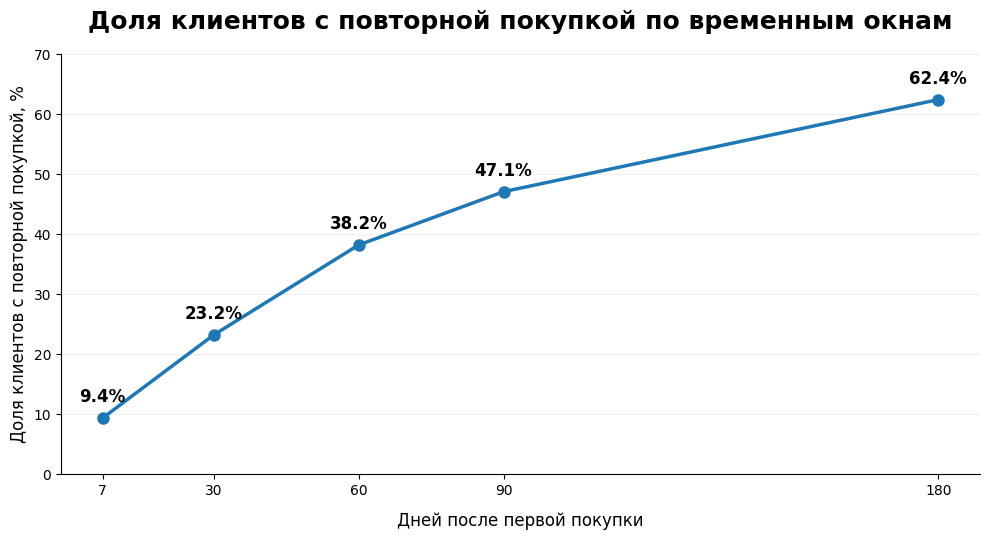

In [ ]:
days = repeat_windows["WindowDays"]
rates = repeat_windows["RepeatRate"]

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(
    days,
    rates,
    marker="o",
    linewidth=2.5,
    markersize=8
)


for x, y in zip(days, rates):
    ax.text(
   x,
   y + 2,
   f"{y:.1f}%",
   ha="center",
   va="bottom",
   fontsize=12,
   fontweight="bold"
    )

ax.set_title(
    "Доля клиентов с повторной покупкой по временным окнам",
    fontsize=18,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Дней после первой покупки",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Доля клиентов с повторной покупкой, %",
    fontsize=12
)

ax.set_xticks(days)
ax.set_ylim(0, 70)


ax.grid(axis="y", alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


plt.tight_layout()
plt.show()

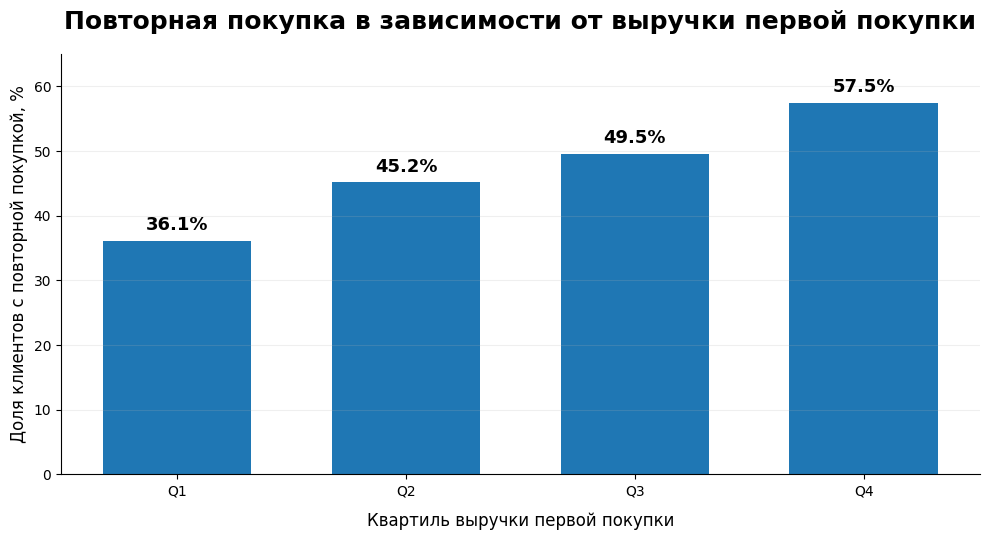

In [ ]:
q_labels = repeat_summary.index.astype(str)
rates = repeat_summary["RepeatRate"]

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(q_labels, rates, width=0.65)

for bar, value in zip(bars, rates):
    ax.text(
   bar.get_x() + bar.get_width() / 2,
   value + 1,
   f"{value:.1f}%",
   ha="center",
   va="bottom",
   fontsize=13,
   fontweight="bold"
    )

ax.set_title(
    "Повторная покупка в зависимости от выручки первой покупки",
    fontsize=18,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Квартиль выручки первой покупки",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Доля клиентов с повторной покупкой, %",
    fontsize=12
)

ax.set_ylim(0, 65)

ax.grid(axis="y", alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

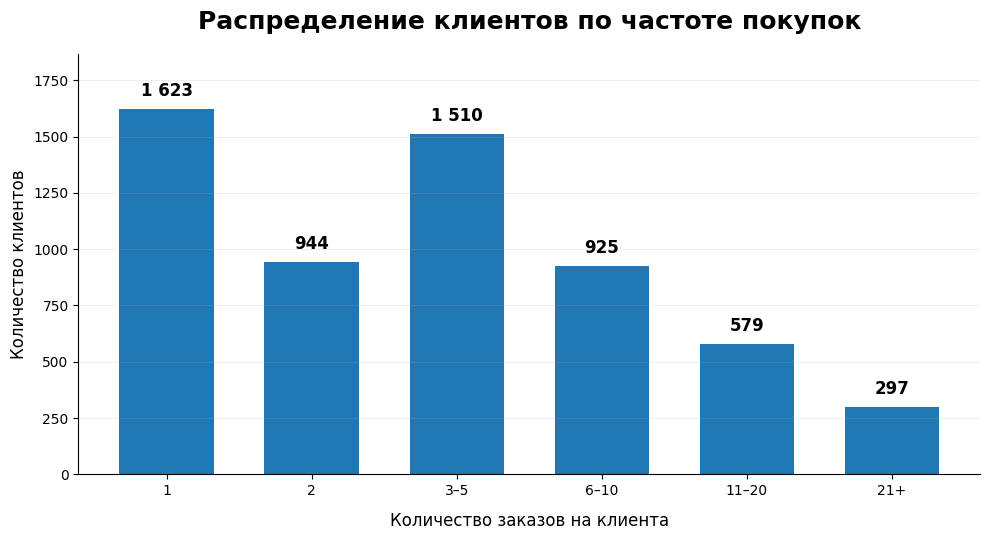

In [ ]:
frequency_counts = (
    customer_value
    .groupby("FrequencyGroup", observed=False)
    .size()
)

groups = frequency_counts.index.astype(str)
customers = frequency_counts.values

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(groups, customers, width=0.65)


for bar, value in zip(bars, customers):
    ax.text(
   bar.get_x() + bar.get_width() / 2,
   value + 40,
   f"{value:,}".replace(",", " "),
   ha="center",
   va="bottom",
   fontsize=12,
   fontweight="bold"
    )

ax.set_title(
    "Распределение клиентов по частоте покупок",
    fontsize=18,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Количество заказов на клиента",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Количество клиентов",
    fontsize=12
)

ax.set_ylim(0, max(customers) * 1.15)


ax.grid(axis="y", alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

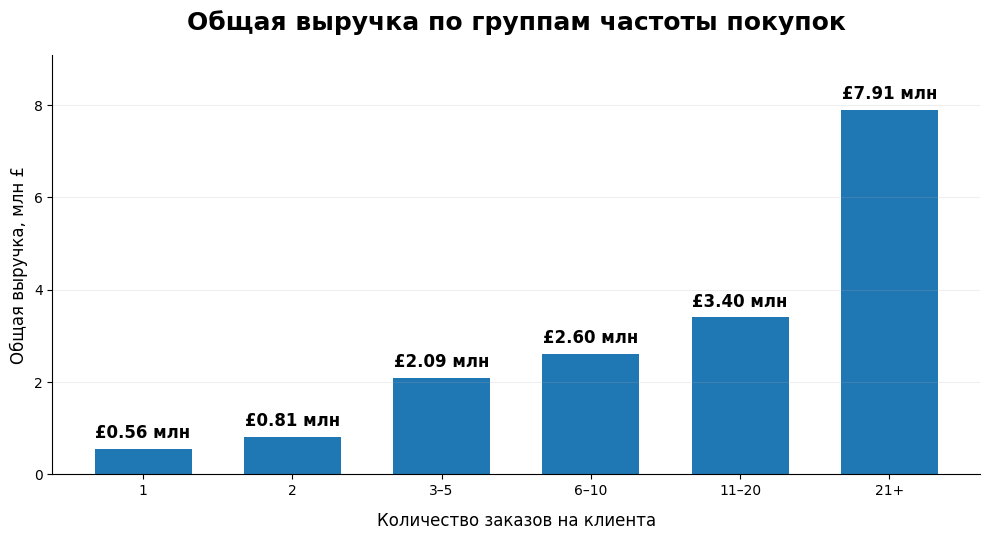

In [ ]:
frequency_revenue = (
    customer_value
    .groupby("FrequencyGroup", observed=False)["TotalRevenue"]
    .sum()
)

groups = frequency_revenue.index.astype(str)
revenue_mln = frequency_revenue.values / 1_000_000

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(groups, revenue_mln, width=0.65)


for bar, value in zip(bars, revenue_mln):
    ax.text(
   bar.get_x() + bar.get_width() / 2,
   value + 0.15,
   f"£{value:.2f} млн",
   ha="center",
   va="bottom",
   fontsize=12,
   fontweight="bold"
    )

ax.set_title(
    "Общая выручка по группам частоты покупок",
    fontsize=18,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Количество заказов на клиента",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Общая выручка, млн £",
    fontsize=12
)

ax.set_ylim(0, max(revenue_mln) * 1.15)


ax.grid(axis="y", alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

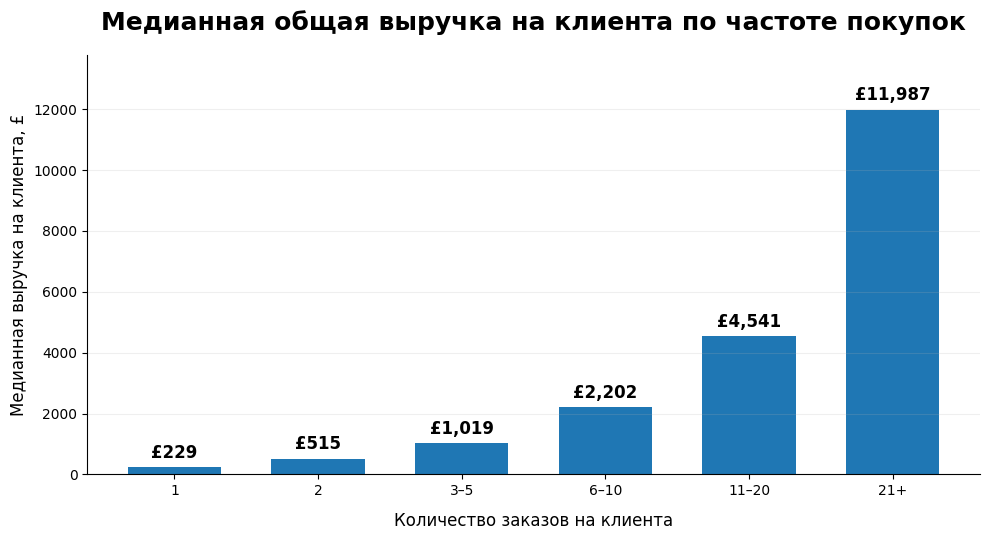

In [ ]:
groups = frequency_value_summary.index.astype(str)
median_revenue = frequency_value_summary["MedianTotalRevenue"]

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(
    groups,
    median_revenue,
    width=0.65
)


for bar, value in zip(bars, median_revenue):
    ax.text(
   bar.get_x() + bar.get_width() / 2,
   value + median_revenue.max() * 0.015,
   f"£{value:,.0f}",
   ha="center",
   va="bottom",
   fontsize=12,
   fontweight="bold"
    )

ax.set_title(
    "Медианная общая выручка на клиента по частоте покупок",
    fontsize=18,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Количество заказов на клиента",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Медианная выручка на клиента, £",
    fontsize=12
)

ax.set_ylim(
    0,
    median_revenue.max() * 1.15
)


ax.grid(axis="y", alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

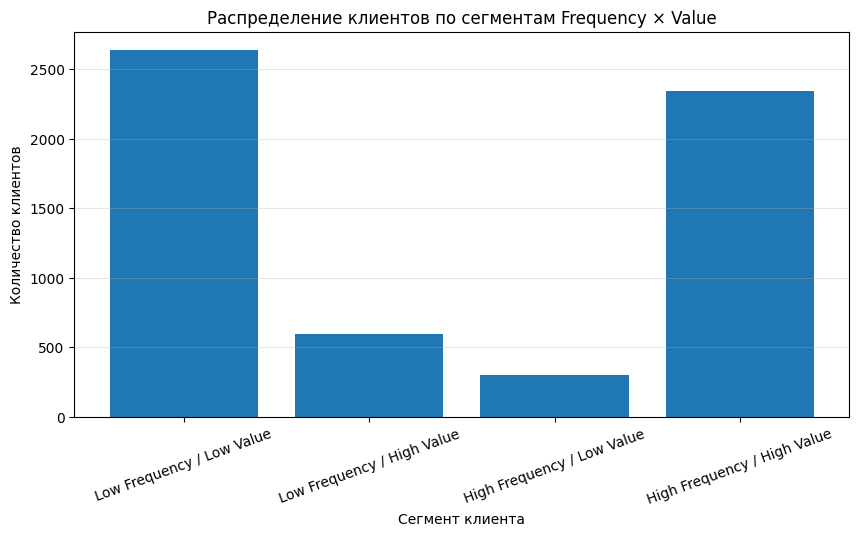

In [ ]:
segment_counts = (
    customer_value["CustomerSegment"]
    .value_counts()
    .reindex([
   "Low Frequency / Low Value",
   "Low Frequency / High Value",
   "High Frequency / Low Value",
   "High Frequency / High Value"
    ])
)

plt.figure(figsize=(10, 5))

plt.bar(
    segment_counts.index,
    segment_counts.values
)

plt.title("Распределение клиентов по сегментам Frequency × Value")
plt.xlabel("Сегмент клиента")
plt.ylabel("Количество клиентов")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.show()

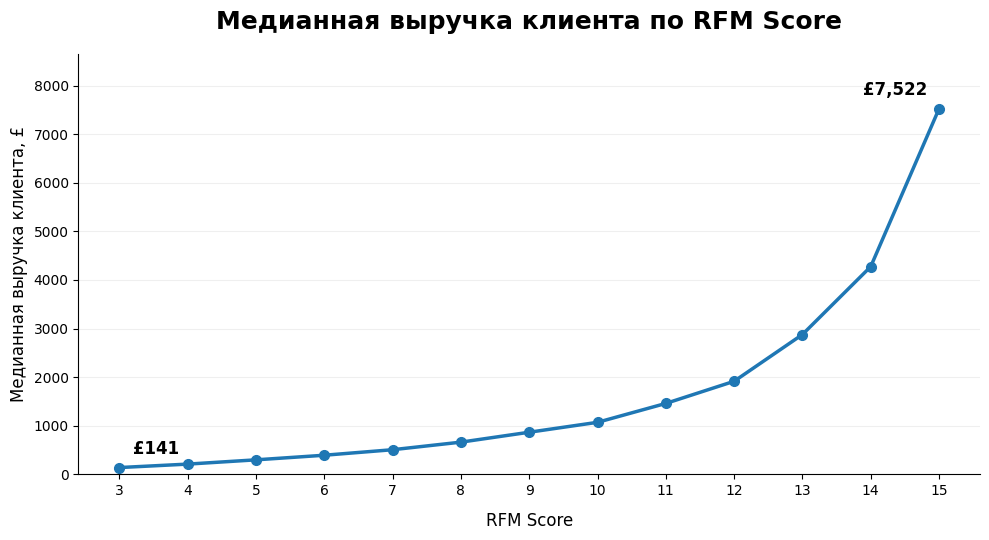

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(
    rfm_summary["RFM_Score"],
    rfm_summary["MedianRevenue"],
    marker="o",
    linewidth=2.5,
    markersize=7
)


first_score = rfm_summary.iloc[0]["RFM_Score"]
first_revenue = rfm_summary.iloc[0]["MedianRevenue"]

last_score = rfm_summary.iloc[-1]["RFM_Score"]
last_revenue = rfm_summary.iloc[-1]["MedianRevenue"]

ax.annotate(
    f"£{first_revenue:,.0f}",
    xy=(first_score, first_revenue),
    xytext=(10, 10),
    textcoords="offset points",
    fontsize=12,
    fontweight="bold"
)

ax.annotate(
    f"£{last_revenue:,.0f}",
    xy=(last_score, last_revenue),
    xytext=(-55, 10),
    textcoords="offset points",
    fontsize=12,
    fontweight="bold"
)


ax.set_title(
    "Медианная выручка клиента по RFM Score",
    fontsize=18,
    fontweight="bold",
    pad=18
)


ax.set_xlabel(
    "RFM Score",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Медианная выручка клиента, £",
    fontsize=12
)


ax.set_xticks(rfm_summary["RFM_Score"])


ax.grid(
    axis="y",
    alpha=0.2
)


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


ax.set_ylim(
    0,
    rfm_summary["MedianRevenue"].max() * 1.15
)

plt.tight_layout()
plt.show()

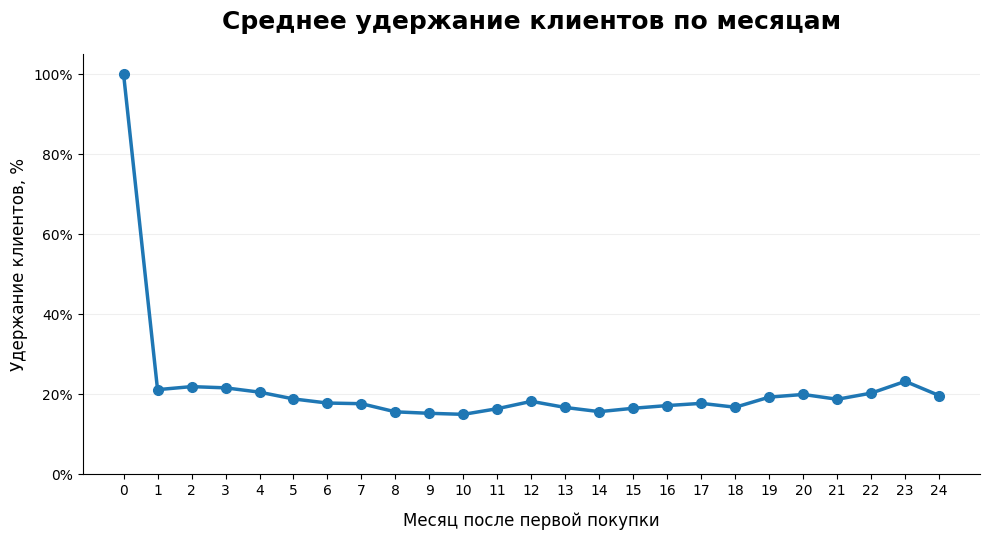

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(
    average_retention.index,
    average_retention.values,
    marker="o",
    linewidth=2.5,
    markersize=7
)

ax.set_title(
    "Среднее удержание клиентов по месяцам",
    fontsize=18,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Месяц после первой покупки",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Удержание клиентов, %",
    fontsize=12
)

ax.set_xticks(average_retention.index)

ax.set_ylim(0, 105)

ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.set_yticklabels(["0%", "20%", "40%", "60%", "80%", "100%"])


ax.grid(axis="y", alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
segment_revenue = (
    customer_value
    .groupby("CustomerSegment", observed=False)["TotalRevenue"]
    .sum()
)

total_revenue = customer_value["TotalRevenue"].sum()

high_freq_high_value_share = (
    segment_revenue["High Frequency / High Value"]
    / total_revenue
    * 100
)

low_freq_high_value_share = (
    segment_revenue["Low Frequency / High Value"]
    / total_revenue
    * 100
)

key_findings = pd.DataFrame({
    "Finding": [
   "90-дневный repeat rate",
   "Repeat rate через 7 дней",
   "Repeat rate через 30 дней",
   "Repeat rate через 60 дней",
   "Repeat rate через 180 дней",
   "Repeat rate: Q1 первой покупки",
   "Repeat rate: Q4 первой покупки",
   "Корреляция частоты и общей выручки",
   "Доля выручки High Frequency / High Value",
   "Доля выручки Low Frequency / High Value",
   "Медианная выручка RFM Score 3",
   "Медианная выручка RFM Score 15"
    ],
    "Value": [
   customer_features["RepeatWithin90Days"].mean() * 100,
   repeat_windows.loc[
   repeat_windows["WindowDays"] == 7, "RepeatRate"
   ].iloc[0],
   repeat_windows.loc[
   repeat_windows["WindowDays"] == 30, "RepeatRate"
   ].iloc[0],
   repeat_windows.loc[
   repeat_windows["WindowDays"] == 60, "RepeatRate"
   ].iloc[0],
   repeat_windows.loc[
   repeat_windows["WindowDays"] == 180, "RepeatRate"
   ].iloc[0],
   repeat_summary.loc["Q1", "RepeatRate"],
   repeat_summary.loc["Q4", "RepeatRate"],
   customer_value[
   ["OrderCount", "TotalRevenue"]
   ].corr().iloc[0, 1],
   high_freq_high_value_share,
   low_freq_high_value_share,
   rfm_summary.loc[
   rfm_summary["RFM_Score"] == 3, "MedianRevenue"
   ].iloc[0],
   rfm_summary.loc[
   rfm_summary["RFM_Score"] == 15, "MedianRevenue"
   ].iloc[0]
    ]
})

key_findings

,Finding,Value
0,90-дневный repeat rate,47.074418
1,Repeat rate через 7 дней,9.392077
2,Repeat rate через 30 дней,23.228966
3,Repeat rate через 60 дней,38.202247
4,Repeat rate через 180 дней,62.407073
5,Repeat rate: Q1 первой покупки,36.109008
6,Repeat rate: Q4 первой покупки,57.500000
7,Корреляция частоты и общей выручки,0.627920
8,Доля выручки High Frequency / High Value,86.485664
9,Доля выручки Low Frequency / High Value,7.088121


In [ ]:
key_findings.to_csv(
    "key_findings.csv",
    index=False
)

print("Файл сохранён: key_findings.csv")

Файл сохранён: key_findings.csv


In [ ]:
import duckdb

sql_frequency_analysis = duckdb.query("""
    SELECT
   FrequencyGroup,
   COUNT(*) AS Customers,
   ROUND(AVG(TotalRevenue), 2) AS MeanTotalRevenue,
   ROUND(MEDIAN(TotalRevenue), 2) AS MedianTotalRevenue
    FROM customer_value
    GROUP BY FrequencyGroup
    ORDER BY
   CASE FrequencyGroup
   WHEN '1' THEN 1
   WHEN '2' THEN 2
   WHEN '3–5' THEN 3
   WHEN '6–10' THEN 4
   WHEN '11–20' THEN 5
   WHEN '21+' THEN 6
   END
""").df()

sql_frequency_analysis

,FrequencyGroup,Customers,MeanTotalRevenue,MedianTotalRevenue
0,1,1623,345.21,228.96
1,2,944,859.57,515.21
2,3–5,1510,1386.71,1018.81
3,6–10,925,2814.29,2201.96
4,11–20,579,5872.12,4541.29
5,21+,297,26619.49,11986.52


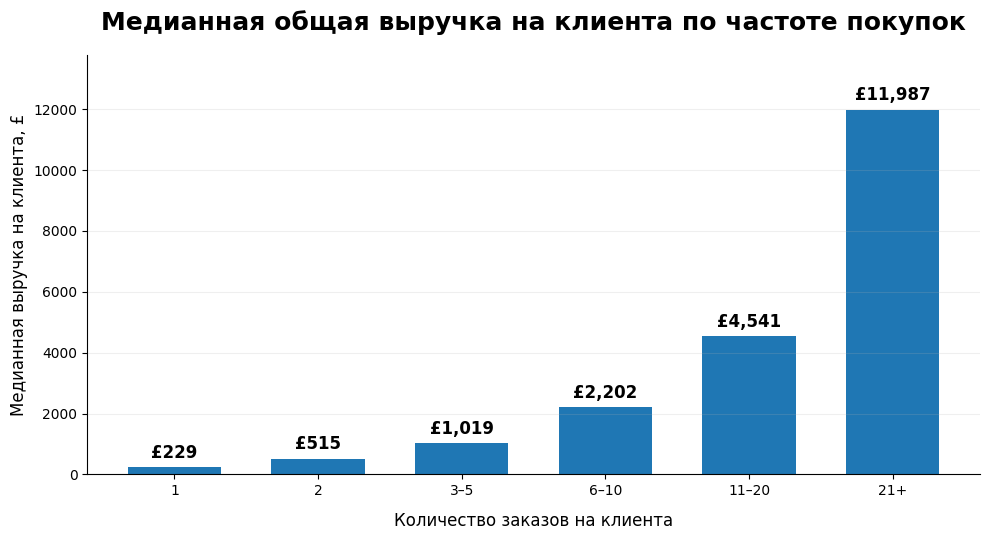

In [ ]:
groups = frequency_value_summary.index.astype(str)
median_revenue = frequency_value_summary["MedianTotalRevenue"]

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(
    groups,
    median_revenue,
    width=0.65
)


for bar, value in zip(bars, median_revenue):
    ax.text(
   bar.get_x() + bar.get_width() / 2,
   value + median_revenue.max() * 0.015,
   f"£{value:,.0f}",
   ha="center",
   va="bottom",
   fontsize=12,
   fontweight="bold"
    )

ax.set_title(
    "Медианная общая выручка на клиента по частоте покупок",
    fontsize=18,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Количество заказов на клиента",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Медианная выручка на клиента, £",
    fontsize=12
)

ax.set_ylim(
    0,
    median_revenue.max() * 1.15
)

ax.grid(
    axis="y",
    alpha=0.2
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
sql_frequency_analysis.to_csv(
    "sql_frequency_analysis.csv",
    index=False
)

print("Файл сохранён: sql_frequency_analysis.csv")

Файл сохранён: sql_frequency_analysis.csv


In [ ]:
sql_customer_segments = duckdb.query("""
    SELECT
   CustomerSegment,
   COUNT(*) AS Customers,
   ROUND(SUM(TotalRevenue), 2) AS TotalRevenue,
   ROUND(
   SUM(TotalRevenue) / SUM(SUM(TotalRevenue)) OVER () * 100,
   2
   ) AS RevenueShare
    FROM customer_value
    GROUP BY CustomerSegment
    ORDER BY TotalRevenue DESC
""").df()

sql_customer_segments

,CustomerSegment,Customers,TotalRevenue,RevenueShare
0,High Frequency / High Value,2345,15026714.87,86.49
1,Low Frequency / High Value,594,1231547.10,7.09
2,Low Frequency / Low Value,2637,928722.09,5.35
3,High Frequency / Low Value,302,187820.20,1.08


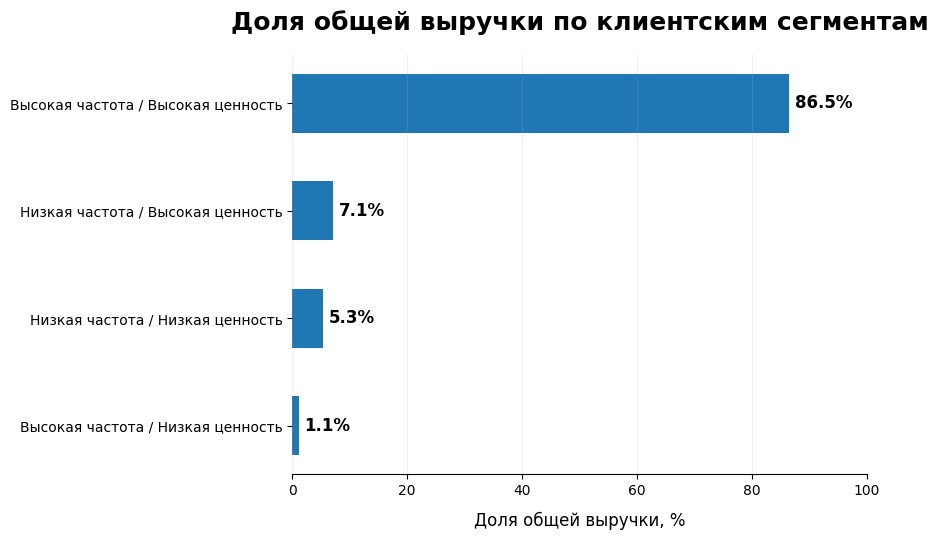

In [ ]:
revenue_share = (
    customer_value
    .groupby("CustomerSegment", observed=False)["TotalRevenue"]
    .sum()
    .sort_values(ascending=True)
)

revenue_share_pct = revenue_share / revenue_share.sum() * 100

labels = [
    "Высокая частота / Высокая ценность",
    "Низкая частота / Высокая ценность",
    "Низкая частота / Низкая ценность",
    "Высокая частота / Низкая ценность"
]

# Переставляем значения в том же порядке
plot_values = pd.Series(
    [
   revenue_share_pct["High Frequency / High Value"],
   revenue_share_pct["Low Frequency / High Value"],
   revenue_share_pct["Low Frequency / Low Value"],
   revenue_share_pct["High Frequency / Low Value"]
    ],
    index=labels
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.barh(
    plot_values.index,
    plot_values.values,
    height=0.55
)

for bar, value in zip(bars, plot_values.values):
    ax.text(
   value + 1,
   bar.get_y() + bar.get_height() / 2,
   f"{value:.1f}%",
   va="center",
   fontsize=12,
   fontweight="bold"
    )

ax.set_title(
    "Доля общей выручки по клиентским сегментам",
    fontsize=18,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Доля общей выручки, %",
    fontsize=12,
    labelpad=10
)

ax.set_xlim(0, 100)

ax.grid(
    axis="x",
    alpha=0.2
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
sql_customer_segments.to_csv(
    "sql_customer_segments.csv",
    index=False
)

print("Файл сохранён: sql_customer_segments.csv")

Файл сохранён: sql_customer_segments.csv


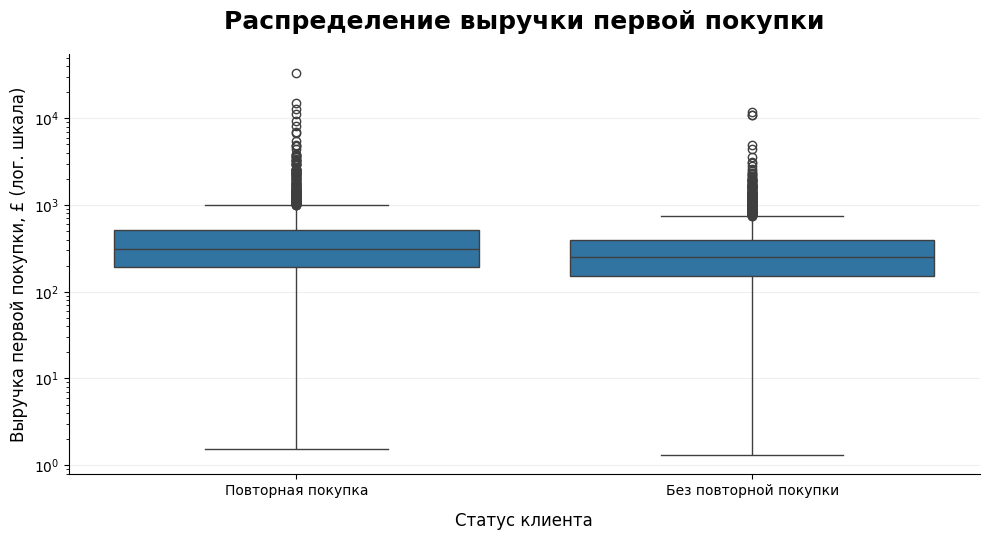

In [ ]:
plot_data = customer_features.copy()

plot_data["Статус клиента"] = plot_data["RepeatWithin90Days"].map({
    False: "Без повторной покупки",
    True: "Повторная покупка"
})

order = [
    "Повторная покупка",
    "Без повторной покупки"
]

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.boxplot(
    data=plot_data,
    x="Статус клиента",
    y="FirstOrderRevenue",
    order=order,
    ax=ax
)


ax.set_yscale("log")

ax.set_title(
    "Распределение выручки первой покупки",
    fontsize=18,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Статус клиента",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Выручка первой покупки, £ (лог. шкала)",
    fontsize=12
)

ax.grid(
    axis="y",
    alpha=0.2
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

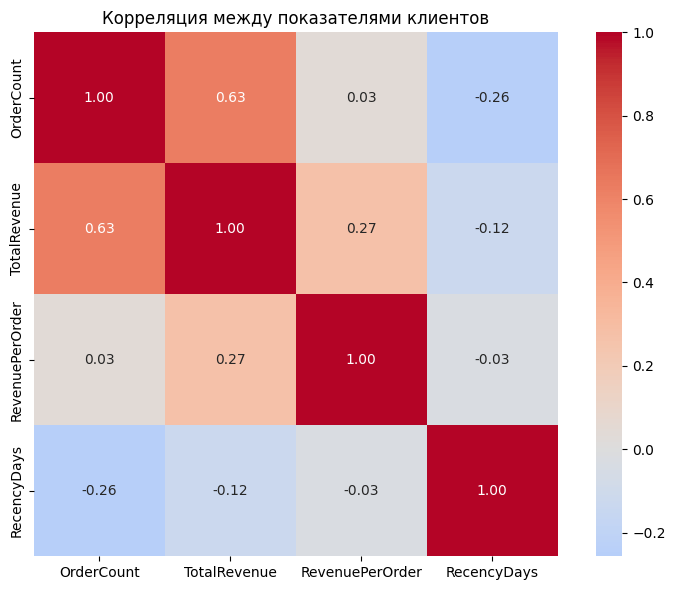

In [ ]:
correlation_data = customer_value[
    [
   "OrderCount",
   "TotalRevenue",
   "RevenuePerOrder",
   "RecencyDays"
    ]
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_data,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Корреляция между показателями клиентов")
plt.tight_layout()
plt.show()